# nb06 — RNA pathway and nearby ATAC comparison

This notebook examines **both positive and negative RNA GSEA NES** from nb04.
Positive NES means enrichment toward E2; negative NES means enrichment toward
Vehicle in the existing E2-versus-Vehicle ranking. This comparison asks whether
nearby accessibility changes agree with those RNA directions. It does not measure
pathway activity directly.

## Scope and methods
Reuse nb04 RNA statistics, the frozen MSigDB v7.0 Hallmarks and nb05 depth-adjusted
peak statistics. Scanpy produced the upstream RNA/ATAC analyses; this notebook
joins those outputs and summarizes them with pandas/NumPy. It does not rerun QC,
normalization, clustering or GSEA.

1. Use **all tested finite-score ATAC peaks**, not just significant peaks. Keep
   only a single nearest gene whose assignment agrees under both coordinate
   interpretations and whose distance is within the specified limit under both.
   Exclude tied nearest-gene assignments; use exact RNA gene symbols without alias
   guessing. Retain the full RNA-tested gene universe, including unmapped genes.
2. For each gene, take the **median signed depth-adjusted ATAC score** across
   eligible peaks. Also retain median raw accessibility-fraction change, peak
   counts, mixed directions, condition-exclusive counts and directional nb05
   candidate counts. A gene's median is a descriptive summary, not a statistical
   gene score or gene-level p-value. Missing peak evidence stays missing, not zero.
3. For every Hallmark, analyze all RNA-tested member genes and, separately, its
   existing RNA GSEA leading-edge genes. Give each mapped gene equal weight.
   Report the fraction of nonzero ATAC gene medians with the same sign as RNA NES,
   its denominator, coverage, opposite/zero counts and the pathway's median ATAC
   score. The ATAC score is **not an NES** and is not calibrated across genes.
   No new pathway p-values or FDR estimates are calculated.
4. Repeat for 100 kb and 10 kb distance limits, each with and without peaks
   detected in only one condition. "Shared detection" means detection in both
   conditions, not biological replication. These sensitivity settings are
   exploratory choices, not paper parameters; 10 kb is not a promoter definition.
5. Preserve all 50 Hallmarks. Untested RNA sets retain missing NES/FDR.
   RNA FDR <= 0.05 is a display flag, not an entry filter. Summaries with fewer
   than 10 mapped genes receive a limited-coverage label; 10 is a display rule,
   not a validated evidence threshold. A majority-direction label describes only
   the observed count and does not establish statistical support.
6. Compare MCF7 and T47D separately and side by side. Pathway memberships overlap,
   so rows do not represent independent evidence.

## Interpretation limits
- RNA GSEA and peak tests are exploratory without identifiable biological
  replicates. Cell counts do not replace independent cultures.
- Residual depth effects, condition/library confounding and cell-state composition
  can produce agreement or disagreement. Removing condition-exclusive peaks is
  a sensitivity analysis, not proof that those peaks are artifacts.
- hg38 is documented, but peak coordinate origin remains unresolved. Nearest-TSS
  assignments are provisional. Coordinate agreement does not validate a target;
  enhancers can act on other genes and accessibility can have complex effects.
- This is a proximity-based directional comparison, **not** paired-cell
  peak-expression correlation, motif enrichment, or validated regulatory linkage.
  Opposing directions need not mean either modality is wrong.
- GSEA permutation estimates reported as zero remain as supplied; zero is not a
  literal probability of no error. RNA FDR cannot be reused as an ATAC FDR.

## Outputs and rerun
Run notebooks/nb06_rna_atac_integration.ipynb after nb04 and nb05.
On Colab mount the project folder in Drive, including the full nb05 DA tables
under data/processed and upstream configs/tables. Code, settings and frozen
Hallmarks are embedded; input tables are required. Local execution does not
validate interactive Drive authorization.

Outputs in results/tables/nb06 include:
- gene evidence for all four mapping scenarios;
- provisional primary peak-to-gene links and pathway gene details;
- pathway summaries for both member subsets and all four scenarios;
- mapping coverage audits, cross-line comparisons, source hashes and validation.

Figures in results/figures/nb06 show both RNA NES directions, ATAC directional
agreement and gene coverage, plus leading-edge sensitivity plots.
Original input files are checked by SHA256 before and after analysis.

## References
- [GSEA User Guide](https://docs.gsea-msigdb.org/GSEA/GSEA_User_Guide/):
  interpretation of enrichment direction and leading-edge subsets.
- [Signac LinkPeaks](https://stuartlab.org/signac/reference/linkpeaks):
  an example of actual peak-expression correlation analysis, which is not
  performed by this proximity comparison.


## 1. Locate project and record environment

In [1]:
try:
    from google.colab import drive
except ImportError:
    IN_COLAB=False
else:
    IN_COLAB=True
    drive.mount('/content/drive')
from pathlib import Path
import os,importlib.util,importlib.metadata,subprocess,sys,json
BASE=Path('/content/drive/MyDrive/breast-cancer-multiome-estrogen') if IN_COLAB else Path(os.environ.get('MULTIOME_PROJECT_ROOT',Path.cwd())).resolve()
if BASE.name=='notebooks': BASE=BASE.parent
packages=['numpy','pandas','matplotlib']
missing=[x for x in packages if importlib.util.find_spec(x) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install',*missing])
VERSIONS={x:importlib.metadata.version(x) for x in packages}
for line in ('MCF7','T47D'):
    for relative in [f'results/tables/nb04/{line}_deg_all.tsv',f'results/tables/nb04/{line}_hallmark_gsea.tsv',
                     f'data/processed/{line}_nb05_da_all.tsv']:
        assert (BASE/relative).is_file(),f'Missing {relative}; run nb04/nb05 first.'
print(BASE, VERSIONS)


/home/shoko/breast-cancer-multiome-estrogen {'numpy': '2.4.6', 'pandas': '2.3.3', 'matplotlib': '3.11.2'}


## 2. Frozen settings and implementation

In [2]:
CONFIG=json.loads('{"rna_gsea_fdr_display": 0.05, "min_mapped_genes_for_direction_summary": 10, "distance_cutoffs_bp": [100000, 10000], "exclude_condition_exclusive": [false, true], "gene_aggregation": "median across all eligible tested peaks; genes equally weighted", "mapping": "single nearest gene only, identical under both coordinate conventions; exact RNA symbol match", "scope": "descriptive, no new pathway significance or causal activity inference"}')
HALLMARKS=json.loads('{"version": "MSigDB v7.0 (frozen; same release as nb03)", "url": "https://raw.githubusercontent.com/broadinstitute/ssGSEA2.0/master/db/msigdb/h.all.v7.0.symbols.gmt", "sha256": "4803c09aae50bbd96d53fc681bd5545a4c89278993c15145dd7b7c994f893516", "gene_sets": {"HALLMARK_TNFA_SIGNALING_VIA_NFKB": ["JUNB", "CXCL2", "ATF3", "NFKBIA", "TNFAIP3", "PTGS2", "CXCL1", "IER3", "CD83", "CCL20", "CXCL3", "MAFF", "NFKB2", "TNFAIP2", "HBEGF", "KLF6", "BIRC3", "PLAUR", "ZFP36", "ICAM1", "JUN", "EGR3", "IL1B", "BCL2A1", "PPP1R15A", "ZC3H12A", "SOD2", "NR4A2", "IL1A", "RELB", "TRAF1", "BTG2", "DUSP1", "MAP3K8", "ETS2", "F3", "SDC4", "EGR1", "IL6", "TNF", "KDM6B", "NFKB1", "LIF", "PTX3", "FOSL1", "NR4A1", "JAG1", "CCL4", "GCH1", "CCL2", "RCAN1", "DUSP2", "EHD1", "IER2", "REL", "CFLAR", "RIPK2", "NFKBIE", "NR4A3", "PHLDA1", "IER5", "TNFSF9", "GEM", "GADD45A", "CXCL10", "PLK2", "BHLHE40", "EGR2", "SOCS3", "SLC2A6", "PTGER4", "DUSP5", "SERPINB2", "NFIL3", "SERPINE1", "TRIB1", "TIPARP", "RELA", "BIRC2", "CXCL6", "LITAF", "TNFAIP6", "CD44", "INHBA", "PLAU", "MYC", "TNFRSF9", "SGK1", "TNIP1", "NAMPT", "FOSL2", "PNRC1", "ID2", "CD69", "IL7R", "EFNA1", "PHLDA2", "PFKFB3", "CCL5", "YRDC", "IFNGR2", "SQSTM1", "BTG3", "GADD45B", "KYNU", "G0S2", "BTG1", "MCL1", "VEGFA", "MAP2K3", "CDKN1A", "CCN1", "TANK", "IFIT2", "IL18", "TUBB2A", "IRF1", "FOS", "OLR1", "RHOB", "AREG", "NINJ1", "ZBTB10", "PLPP3", "KLF4", "CXCL11", "SAT1", "CSF1", "GPR183", "PMEPA1", "PTPRE", "TLR2", "ACKR3", "KLF10", "MARCKS", "LAMB3", "CEBPB", "TRIP10", "F2RL1", "KLF9", "LDLR", "TGIF1", "RNF19B", "DRAM1", "B4GALT1", "DNAJB4", "CSF2", "PDE4B", "SNN", "PLEK", "STAT5A", "DENND5A", "CCND1", "DDX58", "SPHK1", "CD80", "TNFAIP8", "CCNL1", "FUT4", "CCRL2", "SPSB1", "TSC22D1", "B4GALT5", "SIK1", "CLCF1", "NFE2L2", "FOSB", "AC129492.1", "NFAT5", "ATP2B1", "IL12B", "IL6ST", "SLC16A6", "ABCA1", "HES1", "BCL6", "IRS2", "SLC2A3", "CEBPD", "IL23A", "SMAD3", "TAP1", "MSC", "IFIH1", "IL15RA", "TNIP2", "BCL3", "PANX1", "FJX1", "EDN1", "EIF1", "BMP2", "DUSP4", "PDLIM5", "ICOSLG", "GFPT2", "KLF2", "TNC", "SERPINB8", "MXD1"], "HALLMARK_HYPOXIA": ["PGK1", "PDK1", "GBE1", "PFKL", "ALDOA", "ENO2", "PGM1", "NDRG1", "HK2", "ALDOC", "GPI", "MXI1", "SLC2A1", "P4HA1", "ADM", "P4HA2", "ENO1", "PFKP", "AK4", "FAM162A", "PFKFB3", "VEGFA", "BNIP3L", "TPI1", "ERO1A", "KDM3A", "CCNG2", "LDHA", "GYS1", "GAPDH", "BHLHE40", "ANGPTL4", "JUN", "SERPINE1", "LOX", "GCK", "PPFIA4", "MAFF", "DDIT4", "SLC2A3", "IGFBP3", "NFIL3", "FOS", "RBPJ", "HK1", "CITED2", "ISG20", "GALK1", "WSB1", "PYGM", "STC1", "ZNF292", "BTG1", "PLIN2", "CSRP2", "VLDLR", "JMJD6", "EXT1", "F3", "PDK3", "ANKZF1", "UGP2", "ALDOB", "STC2", "ERRFI1", "ENO3", "PNRC1", "HMOX1", "PGF", "GAPDHS", "CHST2", "TMEM45A", "BCAN", "ATF3", "CAV1", "AMPD3", "GPC3", "NDST1", "IRS2", "SAP30", "GAA", "SDC4", "STBD1", "IER3", "PKLR", "IGFBP1", "PLAUR", "CAVIN3", "CCN5", "LARGE1", "NOCT", "S100A4", "RRAGD", "ZFP36", "EGFR", "EDN2", "IDS", "CDKN1A", "RORA", "DUSP1", "MIF", "PPP1R3C", "DPYSL4", "KDELR3", "DTNA", "ADORA2B", "HS3ST1", "CAVIN1", "NR3C1", "KLF6", "GPC4", "CCN1", "TNFAIP3", "CA12", "HEXA", "BGN", "PPP1R15A", "PGM2", "PIM1", "PRDX5", "NAGK", "CDKN1B", "BRS3", "TKTL1", "MT1E", "ATP7A", "MT2A", "SDC3", "TIPARP", "PKP1", "ANXA2", "PGAM2", "DDIT3", "PRKCA", "SLC37A4", "CXCR4", "EFNA3", "CP", "KLF7", "CCN2", "CHST3", "TPD52", "LXN", "B4GALNT2", "PPARGC1A", "BCL2", "GCNT2", "HAS1", "KLHL24", "SCARB1", "SLC25A1", "SDC2", "CASP6", "VHL", "FOXO3", "PDGFB", "B3GALT6", "SLC2A5", "SRPX", "EFNA1", "GLRX", "ACKR3", "PAM", "TGFBI", "DCN", "SIAH2", "PLAC8", "FBP1", "TPST2", "PHKG1", "MYH9", "CDKN1C", "GRHPR", "PCK1", "INHA", "HSPA5", "NDST2", "NEDD4L", "TPBG", "XPNPEP1", "IL6", "SLC6A6", "MAP3K1", "LDHC", "AKAP12", "TES", "KIF5A", "LALBA", "COL5A1", "GPC1", "HDLBP", "ILVBL", "NCAN", "TGM2", "ETS1", "HOXB9", "SELENBP1", "FOSL2", "SULT2B1", "TGFB3"], "HALLMARK_CHOLESTEROL_HOMEOSTASIS": ["FDPS", "CYP51A1", "IDI1", "FDFT1", "DHCR7", "SQLE", "HMGCS1", "NSDHL", "LSS", "MVD", "LDLR", "TM7SF2", "ALDOC", "EBP", "SCD", "PMVK", "MVK", "LPL", "SC5D", "FADS2", "HMGCR", "HSD17B7", "ANXA13", "SREBF2", "PCYT2", "ACSS2", "ATF3", "ADH4", "ETHE1", "ECH1", "CBS", "GUSB", "FASN", "LGALS3", "ATF5", "ANXA5", "TP53INP1", "CHKA", "GSTM2", "ACAT2", "AVPR1A", "PLSCR1", "CLU", "ERRFI1", "TRIB3", "CXCL16", "TNFRSF12A", "ACTG1", "JAG1", "LGMN", "FBXO6", "GPX8", "PNRC1", "ANTXR2", "MAL2", "CD9", "PPARG", "GLDC", "STX5", "STARD4", "CTNNB1", "TMEM97", "FAM129A", "PDK3", "PLAUR", "SEMA3B", "GNAI1", "ABCA2", "ATXN2", "NFIL3", "ALCAM", "FABP5", "S100A11", "CPEB2"], "HALLMARK_MITOTIC_SPINDLE": ["ARHGEF2", "CLASP1", "KIF11", "AC027237.1", "ALS2", "ARF6", "MYO9B", "MYH9", "TUBGCP3", "CKAP5", "RACGAP1", "PREX1", "ARHGEF3", "NUMA1", "SPTBN1", "KIF2C", "KIF5B", "TTK", "APC", "CEP250", "PAFAH1B1", "CDC42EP2", "KIF3B", "CCDC88A", "KIF15", "BIRC5", "CNTROB", "NF1", "TSC1", "CDC27", "CNTRL", "TUBGCP5", "KIF4A", "MAPRE1", "FGD6", "BRCA2", "PLK1", "RASA1", "NEK2", "WASF1", "TOP2A", "TRIO", "ARHGEF11", "KATNB1", "PRC1", "ANLN", "CDK5RAP2", "SMC3", "TUBGCP2", "ESPL1", "MAP1S", "ARHGAP27", "DOCK4", "SAC3D1", "INCENP", "ARHGAP5", "GSN", "NET1", "LRPPRC", "RABGAP1", "FLNB", "ARAP3", "FGD4", "ABR", "CENPJ", "NCK1", "CENPF", "KIF20B", "WASF2", "MYH10", "CENPE", "CYTH2", "MID1", "KLC1", "MARK4", "ARL8A", "CEP57", "UXT", "ARHGAP4", "CDC42EP4", "SASS6", "LATS1", "OPHN1", "WASL", "MAP3K11", "SOS1", "ABL1", "TIAM1", "KIF1B", "ITSN1", "SHROOM1", "NCK2", "DLGAP5", "BCR", "RANBP9", "EPB41L2", "SEPT9", "KATNA1", "TUBD1", "TPX2", "KIF3C", "SHROOM2", "TUBGCP6", "SPTAN1", "PALLD", "ARFIP2", "KNTC1", "HOOK3", "SUN2", "MID1IP1", "DLG1", "FLNA", "ARHGAP10", "CDC42BPA", "ARHGEF12", "MARCKS", "NIN", "PCM1", "RALBP1", "EZR", "SSH2", "CDK1", "RAB3GAP1", "FARP1", "SYNPO", "RHOF", "ECT2", "EPB41", "RAPGEF6", "KIF22", "PCGF5", "STAU1", "ARHGDIA", "AURKA", "FBXO5", "NUSAP1", "PXN", "BCAR1", "CD2AP", "AKAP13", "HDAC6", "CEP131", "LLGL1", "ATG4B", "PCNT", "ALMS1", "KPTN", "DST", "KIFAP3", "PPP4R2", "ARHGAP29", "RASAL2", "CCNB2", "PIF1", "RASA2", "NEDD9", "SMC1A", "ACTN4", "PKD2", "CLIP2", "CDC42", "NDC80", "TLK1", "TAOK2", "TBCD", "CAPZB", "DOCK2", "CTTN", "SMC4", "ARFGEF1", "TUBA4A", "LMNB1", "ABI1", "ROCK1", "CEP192", "BUB1", "GEMIN4", "PLEKHG2", "RICTOR", "BCL2L11", "DYNC1H1", "FSCN1", "ARHGEF7", "DYNLL2", "MYO1E", "BIN1", "NOTCH2", "RFC1", "PDLIM5", "RHOT2", "SORBS2", "CDC42EP1", "VCL", "CLIP1", "STK38L", "YWHAE", "RAPGEF5", "CEP72", "CSNK1D"], "HALLMARK_WNT_BETA_CATENIN_SIGNALING": ["MYC", "CTNNB1", "JAG2", "NOTCH1", "DLL1", "AXIN2", "PSEN2", "FZD1", "NOTCH4", "LEF1", "AXIN1", "NKD1", "WNT5B", "CUL1", "JAG1", "MAML1", "KAT2A", "GNAI1", "WNT6", "PTCH1", "NCOR2", "DKK4", "HDAC2", "DKK1", "TCF7", "WNT1", "NUMB", "ADAM17", "DVL2", "PPARD", "NCSTN", "HDAC5", "CCND2", "FRAT1", "CSNK1E", "RBPJ", "FZD8", "TP53", "SKP2", "HEY2", "HEY1", "HDAC11"], "HALLMARK_TGF_BETA_SIGNALING": ["TGFBR1", "SMAD7", "TGFB1", "SMURF2", "SMURF1", "BMPR2", "SKIL", "SKI", "ACVR1", "PMEPA1", "NCOR2", "SERPINE1", "JUNB", "SMAD1", "SMAD6", "PPP1R15A", "TGIF1", "FURIN", "SMAD3", "FKBP1A", "MAP3K7", "BMPR1A", "CTNNB1", "HIPK2", "KLF10", "BMP2", "ENG", "APC", "PPM1A", "XIAP", "CDH1", "ID1", "LEFTY2", "CDKN1C", "TRIM33", "RAB31", "TJP1", "SLC20A1", "CDK9", "ID3", "NOG", "ARID4B", "IFNGR2", "ID2", "PPP1CA", "SPTBN1", "WWTR1", "BCAR3", "THBS1", "FNTA", "HDAC1", "UBE2D3", "LTBP2", "RHOA"], "HALLMARK_IL6_JAK_STAT3_SIGNALING": ["IL4R", "IL6ST", "STAT1", "IL1R1", "CSF2RB", "SOCS3", "STAT3", "OSMR", "IL2RG", "IFNGR1", "TYK2", "IL13RA1", "TLR2", "IFNGR2", "IL10RB", "IL6", "IL1R2", "IL3RA", "IFNAR1", "TNFRSF1A", "MYD88", "ACVR1B", "CSF3R", "ITGB3", "REG1A", "CXCL1", "A2M", "CSF2RA", "IL15RA", "IRF9", "PDGFC", "HAX1", "BAK1", "EBI3", "INHBE", "CRLF2", "TNFRSF1B", "CD14", "PTPN1", "PTPN2", "IL1B", "CSF1", "IL18R1", "TNF", "PF4", "CXCL13", "AC005840.1", "FAS", "IL17RA", "CXCL10", "IL9R", "STAM2", "TNFRSF12A", "STAT2", "HMOX1", "LEPR", "CBL", "CD9", "CXCL3", "TGFB1", "MAP3K8", "ITGA4", "CD38", "JUN", "SOCS1", "ACVRL1", "PIM1", "TNFRSF21", "PIK3R5", "GRB2", "IRF1", "DNTT", "CSF2", "IL2RA", "PTPN11", "IL12RB1", "CCR1", "CNTFR", "PLA2G2A", "CXCL9", "CD44", "IL7", "CXCL11", "CCL7", "LTB", "IL17RB", "CD36"], "HALLMARK_DNA_REPAIR": ["POLR2H", "POLR2A", "POLR2G", "POLR2E", "POLR2J", "POLR2F", "POLR2C", "POLR2K", "GTF2H3", "POLR2D", "ERCC3", "DDB2", "POLR1C", "XPC", "PCNA", "POLR2I", "SUPT4H1", "POLD3", "POLR3GL", "POLR3C", "GTF2B", "POLR1D", "NCBP2", "NELFE", "GTF2F1", "ERCC5", "LIG1", "ERCC1", "ERCC4", "POLD4", "NELFB", "RFC2", "ELL", "TAF10", "RRM2B", "SUPT5H", "RPA3", "SNAPC5", "SSRP1", "RFC3", "RPA2", "ELOA", "TAF12", "NELFCD", "TAF13", "TAF6", "TAF9", "GTF2A2", "VPS37D", "NME1", "RNMT", "ERCC2", "POLE4", "VPS37B", "NT5C3A", "SNAPC4", "AAAS", "ZNRD1", "RFC4", "ITPA", "POM121", "BRF2", "RFC5", "SAC3D1", "CLP1", "NME4", "PRIM1", "VPS28", "TSG101", "USP11", "TAF1C", "TARBP2", "POLH", "CETN2", "POLD1", "CANT1", "PDE4B", "DGCR8", "RAD51", "SURF1", "PNP", "ADA", "NME3", "GTF3C5", "NT5C", "AK1", "GTF2H1", "HCLS1", "APRT", "ERCC8", "IMPDH2", "POLB", "SDCBP", "SF3A3", "DAD1", "UPF3B", "GUK1", "TP53", "ADRM1", "SEC61A1", "POLA2", "FEN1", "ZNF707", "NUDT9", "AC139530.1", "TYMS", "BCAP31", "DDB1", "NFX1", "RAD52", "ADCY6", "ARL6IP1", "DGUOK", "POLL", "SMAD5", "MPG", "DUT", "POLA1", "AGO4", "RALA", "ZWINT", "BCAM", "TK2", "CSTF3", "GTF2H5", "HPRT1", "BOLA2", "GPX4", "MPC2", "CDA", "ALYREF", "MRPL40", "NPR2", "REV3L", "EDF1", "GSDME", "TMED2", "STX3", "RAE1", "UMPS", "EIF1B", "AK3", "NUDT21", "RBX1", "SRSF6", "GMPR2", "DCTN4", "COX17", "CMPK2", "CCNO"], "HALLMARK_G2M_CHECKPOINT": ["AURKA", "CCNA2", "TOP2A", "CCNB2", "CENPA", "BIRC5", "CDC20", "PLK1", "TTK", "PRC1", "NDC80", "KIF11", "NUSAP1", "CKS2", "KIF2C", "MKI67", "AURKB", "TPX2", "SMC4", "BUB1", "CENPF", "RACGAP1", "CENPE", "AC027237.1", "UBE2C", "MCM6", "MCM3", "PTTG1", "CDK1", "KIF4A", "ESPL1", "MAD2L1", "NEK2", "KIF22", "HMMR", "KPNA2", "CDKN3", "CDC25A", "H2AFX", "CDC25B", "PLK4", "CDC6", "CCNF", "MCM5", "LMNB1", "E2F3", "KIF15", "CHEK1", "UBE2S", "NSD2", "HMGB3", "DBF4", "TACC3", "MCM2", "CDKN2C", "CDKN1B", "FANCC", "NASP", "STAG1", "GINS2", "FBXO5", "POLQ", "EZH2", "RAD21", "STMN1", "SUV39H1", "PRIM2", "E2F1", "CHAF1A", "NOLC1", "GSPT1", "BUB3", "SMC1A", "ILF3", "CDC7", "INCENP", "CKS1B", "EXO1", "H2AFZ", "TFDP1", "CCND1", "KPNB1", "JPT1", "LBR", "HUS1", "KIF20B", "TOP1", "PDS5B", "SRSF1", "STIL", "ABL1", "DTYMK", "CDC27", "BARD1", "ATF5", "CDC45", "ODC1", "XPO1", "SFPQ", "TMPO", "PML", "BRCA2", "CTCF", "KNL1", "KMT5A", "SLC38A1", "TRA2B", "MYBL2", "TROAP", "TENT4A", "CUL3", "MAPK14", "HIST1H2BK", "MYC", "AMD1", "CBX1", "CHMP1A", "DKC1", "YTHDC1", "CCNT1", "TGFB1", "ATRX", "LIG3", "NUP50", "SLC7A5", "RBL1", "NUMA1", "RAD54L", "EFNA5", "PRPF4B", "UCK2", "ARID4A", "CUL1", "UPF1", "DR1", "MNAT1", "SMC2", "RBM14", "RPA2", "SQLE", "ORC6", "CDK4", "POLE", "RASAL2", "HOXC10", "RPS6KA5", "CUL4A", "SLC7A1", "FOXN3", "HMGA1", "AC091021.1", "TRAIP", "PRMT5", "CUL5", "DDX39A", "MARCKS", "PBK", "ORC5", "SAP30", "KATNA1", "HNRNPD", "POLA2", "HIRA", "HIF1A", "SYNCRIP", "TLE3", "NCL", "RAD23B", "E2F2", "EGF", "HMGN2", "SRSF10", "SNRPD1", "CASP8AP2", "SMARCC1", "SLC12A2", "NOTCH2", "TNPO2", "SMAD3", "MAP3K20", "HSPA8", "G3BP1", "PTTG3P", "DMD", "MEIS1", "HNRNPU", "SRSF2", "MT2A", "NUP98", "EWSR1", "KIF5B", "MTF2", "E2F4", "BCL3", "PURA", "MEIS2", "PAFAH1B1", "WRN", "H2AFV", "ODF2"], "HALLMARK_APOPTOSIS": ["CASP3", "CASP9", "DFFA", "CASP7", "CFLAR", "BIRC3", "PMAIP1", "CASP8", "JUN", "BCL2L11", "MCL1", "IL1B", "SPTAN1", "DIABLO", "BAX", "BIK", "IL1A", "BID", "CDKN1A", "GADD45A", "DDIT3", "CDKN1B", "TNF", "GSN", "TNFSF10", "CASP6", "SQSTM1", "FASLG", "EGR3", "CD44", "FAS", "IL18", "IGFBP6", "PRF1", "DAP", "CCND1", "BTG3", "F2R", "SATB1", "BNIP3L", "CASP4", "TNFRSF12A", "CREBBP", "RHOB", "GPX3", "PDGFRB", "TSPO", "CCND2", "XIAP", "TIMP1", "CTNNB1", "IRF1", "HSPB1", "ADD1", "TIMP2", "BTG2", "TIMP3", "LEF1", "CASP1", "GPX1", "BCL10", "IGF2R", "CDC25B", "AIFM3", "CD38", "PPP3R1", "HGF", "CLU", "ATF3", "LGALS3", "LUM", "LMNA", "GADD45B", "CDK2", "IFNB1", "RETSAT", "SMAD7", "SOD1", "PTK2", "ENO2", "HMOX1", "IER3", "BCL2L10", "CD2", "GCH1", "MMP2", "VDAC2", "TAP1", "PLAT", "IFNGR1", "APP", "BRCA1", "ROCK1", "PSEN1", "DCN", "PSEN2", "SOD2", "BMF", "EREG", "KRT18", "TGFB2", "RELA", "WEE1", "RARA", "CD14", "CD69", "PEA15", "DNAJC3", "CASP2", "CTH", "PLCB2", "BMP2", "HMGB2", "PLPPR4", "H1F0", "TGFBR3", "EBP", "TXNIP", "ANKH", "RHOT2", "CYLD", "GSTM1", "GSR", "BGN", "BCL2L1", "GNA15", "MGMT", "PPT1", "F2", "IL6", "SC5D", "IFITM3", "RNASEL", "EMP1", "CAV1", "DNM1L", "ANXA1", "TOP2A", "ISG20", "SLC20A1", "MADD", "PPP2R5B", "BCAP31", "ERBB3", "NEDD9", "SAT1", "PDCD4", "BCL2L2", "FEZ1", "ERBB2", "DNAJA1", "DAP3", "DPYD", "NEFH", "PAK1", "FDXR", "GPX4", "ETF1", "CCNA1", "GUCY2D", "AVPR1A"], "HALLMARK_NOTCH_SIGNALING": ["JAG1", "NOTCH3", "NOTCH2", "APH1A", "HES1", "CCND1", "FZD1", "PSEN2", "FZD7", "DTX1", "DLL1", "FZD5", "MAML2", "NOTCH1", "PSENEN", "WNT5A", "CUL1", "WNT2", "DTX4", "SAP30", "PPARD", "KAT2A", "HEYL", "SKP1", "RBX1", "TCF7L2", "ARRB1", "LFNG", "PRKCA", "DTX2", "ST3GAL6", "FBXW11"], "HALLMARK_ADIPOGENESIS": ["FABP4", "ADIPOQ", "PPARG", "LIPE", "DGAT1", "LPL", "CPT2", "CD36", "GPAM", "ADIPOR2", "ACAA2", "ETFB", "ACOX1", "ACADM", "HADH", "IDH1", "SORBS1", "ACADS", "UCK1", "SCP2", "DECR1", "CDKN2C", "TALDO1", "TST", "MCCC1", "PGM1", "REEP5", "BCL2L13", "SLC25A10", "ME1", "PHYH", "PIM3", "YWHAG", "NDUFAB1", "GPD2", "ADIG", "ECHS1", "QDPR", "CS", "ECH1", "SLC25A1", "ACADL", "TOB1", "GRPEL1", "CRAT", "GBE1", "CAVIN2", "SCARB1", "PEMT", "CHCHD10", "AK2", "APOE", "UQCR10", "TANK", "ANGPTL4", "ACO2", "FAH", "ACLY", "IFNGR1", "SLC5A6", "JAGN1", "EPHX2", "IDH3G", "GPX3", "ELMOD3", "ORM1", "RETSAT", "ESRRA", "HIBCH", "SUCLG1", "STAT5A", "ITGA7", "MRAP", "PLIN2", "CYC1", "ALDH2", "RNF11", "ALDOA", "SULT1A1", "DDT", "SDHB", "CD151", "SLC27A1", "BCKDHA", "C3", "LEP", "ADCY6", "ELOVL6", "LTC4S", "SPARCL1", "RMDN3", "MTCH2", "SOWAHC", "SLC1A5", "CMPK1", "REEP6", "NDUFA5", "FZD4", "DRAM2", "MGST3", "ATP1B3", "RETN", "STOM", "ESYT1", "GHITM", "DNAJC15", "GADD45A", "VEGFB", "PFKL", "COQ3", "NABP1", "CYP4B1", "PPM1B", "ARAF", "CAVIN1", "COL4A1", "IMMT", "DHRS7", "COL15A1", "NMT1", "COQ5", "LAMA4", "AGPAT3", "BAZ2A", "IDH3A", "LIFR", "PREB", "PTGER3", "GPHN", "PFKFB3", "GPX4", "SSPN", "SQOR", "MARC2", "DLD", "ITIH5", "CD302", "ATL2", "GPAT4", "LPCAT3", "TKT", "UQCRC1", "CAT", "OMD", "DLAT", "MRPL15", "RIOK3", "RTN3", "CHUK", "G3BP2", "SDHC", "SAMM50", "ARL4A", "SNCG", "PDCD4", "COQ9", "APLP2", "SOD1", "PTCD3", "PHLDB1", "ENPP2", "HSPB8", "AIFM1", "CCNG2", "PPP1R15B", "MDH2", "ABCA1", "COX7B", "MYLK", "COX8A", "DHRS7B", "MIGA2", "MGLL", "ITSN1", "DHCR7", "RREB1", "CMBL", "UBC", "ATP5PO", "PRDX3", "DBT", "NDUFS3", "NKIRAS1", "RAB34", "CIDEA", "UQCRQ", "PEX14", "BCL6", "COX6A1", "DNAJB9", "MAP4K3", "ANGPT1", "UBQLN1", "NDUFB7", "SLC19A1", "ABCB8", "PQLC3", "POR", "UCP2", "UQCR11"], "HALLMARK_ESTROGEN_RESPONSE_EARLY": ["GREB1", "CA12", "SLC9A3R1", "MYB", "ANXA9", "IGFBP4", "SYBU", "NPY1R", "PDZK1", "NRIP1", "MLPH", "HSPB8", "EGR3", "KRT19", "LRIG1", "KDM4B", "PGR", "RHOBTB3", "TPD52L1", "ELOVL2", "RET", "TPBG", "TFF1", "MAPT", "SCNN1A", "ABAT", "FLNB", "XBP1", "CELSR2", "RAB31", "MYBL1", "MREG", "FAM102A", "MSMB", "STC2", "RETREG1", "SIAH2", "ZNF185", "SLC19A2", "SLC1A4", "FHL2", "BCL2", "PMAIP1", "AREG", "OVOL2", "TSKU", "ADCY9", "RASGRP1", "MUC1", "KAZN", "SLC27A2", "FKBP4", "CXCL12", "TMPRSS3", "RARA", "IL17RB", "CBFA2T3", "TFF3", "UGCG", "CCND1", "SLC22A5", "WFS1", "PTGES", "WWC1", "CCN5", "MYC", "ITPK1", "TMEM164", "ARL3", "MED13L", "SEMA3B", "KRT18", "SLC16A1", "TJP3", "SLC26A2", "FCMR", "SULT2B1", "SNX24", "TFAP2C", "TTC39A", "GJA1", "PRSS23", "OLFM1", "RAPGEFL1", "ASB13", "TIPARP", "ABCA3", "FRK", "DHRS2", "AQP3", "KCNK15", "TGIF2", "FOXC1", "ELF3", "REEP1", "PEX11A", "PODXL", "KLF4", "BAG1", "CELSR1", "PLAAT3", "SLC7A5", "MPPED2", "TIAM1", "CLDN7", "MYOF", "RBBP8", "OLFML3", "GFRA1", "FARP1", "SVIL", "TGM2", "DEPTOR", "CYP26B1", "PAPSS2", "SLC1A1", "DLC1", "JAK2", "AFF1", "KLK10", "P2RY2", "BLVRB", "CISH", "GLA", "ADD3", "PDLIM3", "MINDY1", "FOS", "KRT8", "SLC37A1", "B4GALT1", "CALCR", "ESRP2", "IGF1R", "NBL1", "SFN", "OPN3", "ABHD2", "AR", "SLC39A6", "SYT12", "CD44", "MED24", "BCL11B", "CANT1", "KRT13", "KRT15", "TOB1", "SLC7A2", "LAD1", "TUBB2B", "TBC1D30", "SEC14L2", "ENDOD1", "HR", "SCARB1", "NCOR2", "RHOD", "INPP5F", "PPIF", "DHRS3", "FDFT1", "GAB2", "UNC119", "KLF10", "HES1", "FKBP5", "SLC2A1", "AMFR", "NADSYN1", "INHBB", "BHLHE40", "CALB2", "FASN", "CHPT1", "MYBBP1A", "ELOVL5", "DYNLT3", "ABLIM1", "SOX3", "SLC24A3", "RAB17", "MAST4", "KCNK5", "ELF1", "RPS6KA2", "ISG20L2", "IL6ST", "SYNGR1", "SH3BP5", "ALDH3B1", "THSD4", "CLIC3", "NXT1", "NAV2", "RRP12", "ADCY1", "DHCR7", "MICB", "AKAP1"], "HALLMARK_ESTROGEN_RESPONSE_LATE": ["TFF1", "SLC9A3R1", "TPD52L1", "PRSS23", "CA12", "PDZK1", "ANXA9", "CELSR2", "TJP3", "PGR", "RET", "MYB", "TPBG", "EGR3", "ARL3", "OLFM1", "NPY1R", "SCNN1A", "XBP1", "AREG", "IL17RB", "NRIP1", "ASS1", "TFF3", "FKBP4", "SLC27A2", "SEMA3B", "GPER1", "LLGL2", "AGR2", "KRT19", "CCN5", "BLVRB", "FLNB", "PDCD4", "CALCR", "IGFBP4", "DNAJC12", "TIAM1", "TSPAN13", "CXCL12", "RAB31", "PKP3", "CYP26B1", "FKBP5", "SIAH2", "ISG20", "TMPRSS3", "SERPINA3", "WFS1", "MAPT", "PDLIM3", "RBBP8", "GJB3", "PRLR", "SLC1A4", "FOS", "PLAAT3", "SLC7A5", "SERPINA5", "IMPA2", "DHCR7", "MYOF", "CDH1", "EMP2", "OVOL2", "DLG5", "SOX3", "CHPT1", "KLK10", "ELOVL5", "RAPGEFL1", "JAK2", "SLC26A2", "SLC22A5", "ITPK1", "PCP4", "PAPSS2", "NAB2", "FAM102A", "BCL2", "LSR", "CACNA2D2", "CA2", "ASCL1", "ACOX2", "CISH", "GLA", "PTGES", "PERP", "OPN3", "KRT13", "HSPB8", "UGDH", "CLIC3", "KLK11", "PLAC1", "ABHD2", "SCARB1", "DCXR", "CCND1", "SFN", "ABCA3", "SULT2B1", "CCNA1", "STIL", "MICB", "ZFP36", "CAV1", "NBL1", "CD44", "HR", "HOMER2", "BTG3", "GAL", "ETFB", "BAG1", "FRK", "SLC16A1", "AFF1", "TFAP2C", "IGSF1", "HPRT1", "CDC6", "FARP1", "AMFR", "DHRS2", "NXT1", "S100A9", "SLC29A1", "SLC24A3", "FOXC1", "KIF20A", "TOB1", "FDFT1", "DNAJC1", "TPSAB1", "TSTA3", "FGFR3", "SGK1", "ID2", "GALE", "BATF", "MAPK13", "FABP5", "MEST", "JAK1", "CYP4F11", "KCNK5", "CPE", "XRCC3", "CXCL14", "SCUBE2", "CDC20", "IL6ST", "GINS2", "TRIM29", "UNC13B", "LAMC2", "LARGE1", "SLC2A8", "PLXNB1", "PRKAR2B", "RPS6KA2", "HSPA4L", "TFPI2", "SERPINA1", "TNNC1", "HMGCS2", "ALDH3A2", "CD9", "IDH2", "SORD", "MDK", "ALDH3B1", "PTGER3", "RABEP1", "KLF4", "PPIF", "SNX10", "METTL3", "PLK4", "COX6C", "ST14", "NCOR2", "MOCS2", "NMU", "TH", "RNASEH2A", "CHST8", "TST", "TOP2A", "CKB", "LTF", "DUSP2", "PTPN6", "ATP2B4", "ST6GALNAC2", "ADD3", "DYNLT3"], "HALLMARK_ANDROGEN_RESPONSE": ["KLK3", "KLK2", "ACSL3", "PIAS1", "CAMKK2", "NKX3-1", "TMPRSS2", "APPBP2", "CENPN", "BMPR1B", "MAF", "FADS1", "ZBTB10", "HMGCR", "SPCS3", "INSIG1", "NGLY1", "UBE2J1", "ELK4", "ABCC4", "ELOVL5", "ALDH1A3", "AZGP1", "ABHD2", "SAT1", "DBI", "DHCR24", "SORD", "STK39", "TPD52", "IDI1", "B2M", "MAP7", "DNAJB9", "FKBP5", "HERC3", "PGM3", "HOMER2", "ELL2", "UAP1", "SEC24D", "LMAN1", "PMEPA1", "INPP4B", "RRP12", "SELENOP", "NDRG1", "KRT19", "ITGAV", "B4GALT1", "MAK", "SPDEF", "GSR", "KRT8", "LIFR", "PLPP1", "STEAP4", "GUCY1A1", "SRP19", "CCND3", "IQGAP2", "RAB4A", "SLC26A2", "SMS", "ZMIZ1", "SGK1", "MERTK", "HPGD", "ANKH", "GNAI3", "SRF", "SLC38A2", "HMGCS1", "ARID5B", "CDC14B", "TNFAIP8", "XRCC5", "GPD1L", "ACTN1", "RPS6KA3", "TSC22D1", "PDLIM5", "TMEM50A", "ADAMTS1", "NCOA4", "AKAP12", "SCD", "PTK2B", "CDK6", "ADRM1", "H1F0", "HSD17B14", "VAPA", "CCND1", "XRCC6", "MYL12A", "UBE2I", "AL162171.1", "AKT1", "PA2G4"], "HALLMARK_MYOGENESIS": ["ACTA1", "TNNI2", "MYL1", "TNNC1", "TNNC2", "MYH3", "MYLPF", "TNNT3", "TNNT2", "CASQ2", "ACTC1", "MYOM1", "MYL4", "MYBPH", "MYH7", "MYH8", "ACTN2", "TNNI1", "CRYAB", "SGCG", "HRC", "TNNT1", "DES", "MYOZ1", "RYR1", "CSRP3", "ADAM12", "ATP2A1", "CKM", "SVIL", "MYOM2", "MYL6B", "TPM2", "MYL2", "CKMT2", "BIN1", "MYH1", "ENO3", "FLII", "FXYD1", "TPM3", "DMD", "IGFBP3", "CHRNB1", "SPEG", "FHL1", "ACTN3", "TCAP", "MYLK", "MYL3", "PYGM", "LDB3", "COX6A2", "FABP3", "MYL7", "ITGB5", "CHRNA1", "SSPN", "COL3A1", "KCNH1", "GJA5", "MYF6", "MYH2", "MAPK12", "PGAM2", "MYOG", "MYH4", "AEBP1", "HBEGF", "MEF2C", "NOS1", "CNN3", "IGFBP7", "CACNA1H", "GSN", "CACNG1", "PPFIA4", "MB", "SPHK1", "SCHIP1", "MEF2D", "SMTN", "CDKN1A", "GAA", "TPD52L1", "HSPB2", "SGCA", "BDKRB2", "COX7A1", "COL4A2", "PLXNB2", "CTF1", "COL15A1", "KCNH2", "AGRN", "MYO1C", "SIRT2", "SGCD", "SORBS1", "VIPR1", "FGF2", "FKBP1B", "TEAD4", "CASQ1", "KLF5", "PDLIM7", "AK1", "TAGLN", "RIT1", "MEF2A", "ANKRD2", "AKT2", "LAMA2", "ST5", "IFRD1", "NCAM1", "SYNGR2", "PICK1", "COL6A3", "CRAT", "DMPK", "MYH11", "MYH9", "IGF1", "CKB", "FST", "GPX3", "PVALB", "PTP4A3", "ITGB1", "HSPB8", "ACHE", "CHRNG", "PKIA", "NAV2", "HDAC5", "ATP6AP1", "CLU", "ACSL1", "COL1A1", "MRAS", "PDE4DIP", "AGL", "ERBB3", "GABARAPL2", "CAV3", "BHLHE40", "PPP1R3C", "LARGE1", "LPIN1", "CDH13", "NQO1", "PRNP", "PSEN2", "DAPK2", "LSP1", "SLC6A8", "REEP1", "EIF4A2", "SH2B1", "MYBPC3", "ITGA7", "SPTAN1", "SORBS3", "PC", "SCD", "GNAO1", "STC2", "CFD", "RB1", "BAG1", "ABLIM1", "PTGIS", "MAPRE3", "OCEL1", "SH3BGR", "NOTCH1", "TSC2", "TGFB1", "FDPS", "CAMK2B", "EPHB3", "GADD45B", "APP", "APLNR", "ITGB4", "SOD3", "FOXO4", "EFS", "PFKM", "COL6A2", "DTNA", "KIFC3", "SPARC", "SPDEF", "SLN", "WWTR1", "CD36", "ADCY9", "APOD"], "HALLMARK_PROTEIN_SECRETION": ["ARCN1", "TMED10", "COPB2", "RAB14", "ATP7A", "COPB1", "LAMP2", "EGFR", "IGF2R", "COPE", "PPT1", "AP3S1", "BET1", "CLCN3", "AP2S1", "CLTC", "AP2M1", "RER1", "KIF1B", "ARF1", "OCRL", "ICA1", "MON2", "ARFGEF2", "TMED2", "NAPG", "TMX1", "PAM", "SCAMP1", "SH3GL2", "RAB2A", "COG2", "VAMP3", "ERGIC3", "DOP1A", "VAMP4", "VPS4B", "NAPA", "GNAS", "STX7", "SEC22B", "VPS45", "STX16", "YKT6", "SNX2", "ARFGEF1", "CLTA", "CLN5", "M6PR", "SGMS1", "USO1", "TSG101", "DNM1L", "LMAN1", "YIPF6", "ARFIP1", "ANP32E", "TSPAN8", "DST", "SCRN1", "SEC31A", "VAMP7", "SCAMP3", "AP2B1", "RAB22A", "AP3B1", "TPD52", "ATP6V1H", "GBF1", "KRT18", "CAV2", "ATP1A1", "BNIP3", "ZW10", "GALC", "ADAM10", "RAB5A", "GOLGA4", "SEC24D", "AP1G1", "MAPK1", "GOSR2", "RPS6KA3", "STAM", "ABCA1", "SNAP23", "SOD1", "GLA", "ATP6V1B1", "STX12", "CD63", "TOM1L1", "SSPN", "ARFGAP3", "RAB9A", "CTSC"], "HALLMARK_INTERFERON_ALPHA_RESPONSE": ["MX1", "ISG15", "AC004551.1", "IFIT3", "IFI44", "IFI35", "IRF7", "RSAD2", "IFI44L", "IFITM1", "IFI27", "IRF9", "OASL", "EIF2AK2", "IFIT2", "CXCL10", "TAP1", "SP110", "DDX60", "UBE2L6", "USP18", "PSMB8", "IFIH1", "BST2", "LGALS3BP", "ADAR", "ISG20", "GBP2", "IRF1", "PLSCR1", "PSMB9", "HERC6", "SAMD9", "CMPK2", "IFITM3", "RTP4", "STAT2", "SAMD9L", "LY6E", "IFITM2", "HELZ2", "CXCL11", "TRIM21", "PARP14", "TRIM26", "PARP12", "NMI", "RNF31", "HLA-C", "CASP1", "TRIM14", "TDRD7", "DHX58", "PARP9", "PNPT1", "TRIM25", "PSME1", "WARS", "EPSTI1", "UBA7", "PSME2", "B2M", "TRIM5", "C1S", "LAP3", "LAMP3", "GBP4", "NCOA7", "TMEM140", "CD74", "GMPR", "PSMA3", "PROCR", "IL7", "IFI30", "IRF2", "CSF1", "IL15", "CNP", "TENT5A", "IL4R", "CMTR1", "CD47", "LPAR6", "MOV10", "CASP8", "TXNIP", "SLC25A28", "SELL", "TRAFD1", "BATF2", "RIPK2", "CCRL2", "NUB1", "OGFR", "MVB12A", "ELF1"], "HALLMARK_INTERFERON_GAMMA_RESPONSE": ["STAT1", "ISG15", "IFIT1", "MX1", "IFIT3", "IFI35", "IRF7", "IFIT2", "OAS2", "TAP1", "EIF2AK2", "RSAD2", "MX2", "IRF1", "OAS3", "TNFSF10", "IRF9", "CXCL10", "IFI44", "BST2", "XAF1", "SP110", "OASL", "PSMB8", "IFI44L", "IFITM3", "DDX60", "LGALS3BP", "GBP4", "IRF8", "PSMB9", "PML", "IFIH1", "UBE2L6", "IFI27", "ADAR", "LY6E", "STAT2", "CXCL9", "IL10RA", "PLA2G4A", "TRIM21", "USP18", "PTGS2", "EPSTI1", "C1S", "DDX58", "IL15", "NLRC5", "NMI", "IDO1", "PSMB10", "CXCL11", "ITGB7", "SAMHD1", "HERC6", "CMPK2", "SAMD9L", "RTP4", "PTPN2", "PARP14", "TNFAIP2", "IFITM2", "PLSCR1", "SOCS1", "CASP1", "ICAM1", "WARS", "PSME1", "ISG20", "IRF2", "TRIM14", "FCGR1A", "MARCH1", "SOCS3", "JAK2", "HLA-DMA", "PARP12", "TNFAIP6", "TRIM26", "VCAM1", "CD274", "CIITA", "NAMPT", "SELP", "GPR18", "FPR1", "HELZ2", "PSME2", "SERPING1", "CCL5", "RNF31", "SOD2", "TRIM25", "LAP3", "PSMA3", "AC124319.1", "PELI1", "CFB", "CD86", "TXNIP", "HLA-DQA1", "GCH1", "PNP", "CCL7", "PTPN6", "SPPL2A", "IL4R", "PNPT1", "DHX58", "BTG1", "CASP8", "IFI30", "CCL2", "FGL2", "CASP7", "SECTM1", "IL15RA", "CD40", "TRAFD1", "HLA-DRB1", "GBP6", "LCP2", "HLA-G", "MT2A", "RIPK1", "KLRK1", "UPP1", "PSMB2", "TDRD7", "HIF1A", "EIF4E3", "VAMP8", "PFKP", "CD38", "ZBP1", "BANK1", "TOR1B", "RBCK1", "PDE4B", "MVP", "IL7", "BPGM", "CMTR1", "AUTS2", "B2M", "RIPK2", "CD69", "MYD88", "PSMA2", "PIM1", "NOD1", "CFH", "TAPBP", "SLC25A28", "PTPN1", "TNFAIP3", "SSPN", "NUP93", "MTHFD2", "CDKN1A", "IRF4", "NFKB1", "BATF2", "HLA-B", "LATS2", "IRF5", "SLAMF7", "ISOC1", "P2RY14", "STAT3", "NCOA3", "HLA-A", "IL6", "GZMA", "IFNAR2", "CD74", "RAPGEF6", "CASP4", "FAS", "OGFR", "ARL4A", "SRI", "LYSMD2", "CSF2RB", "ST3GAL5", "C1R", "CASP3", "CMKLR1", "NFKBIA", "METTL7B", "ST8SIA4", "XCL1", "IL2RB", "VAMP5", "IL18BP", "ZNFX1", "ARID5B", "APOL6", "STAT4"], "HALLMARK_APICAL_JUNCTION": ["ACTN1", "CLDN7", "ACTN3", "CLDN19", "DLG1", "TJP1", "COL17A1", "NECTIN1", "CLDN9", "CDH3", "CTNND1", "CDH1", "LIMA1", "VCL", "SHROOM2", "NECTIN3", "NECTIN2", "CLDN14", "PTPRC", "THY1", "VASP", "ITGB1", "ZYX", "ACTN4", "CLDN4", "CADM3", "ITGA3", "NF2", "B4GALT1", "NEXN", "CDH6", "ADAM15", "PTK2", "HADH", "LAMB3", "CLDN11", "CDH4", "IRS1", "SORBS3", "CLDN8", "EVL", "CLDN15", "THBS3", "NECTIN4", "JAM3", "CDH11", "ITGB4", "RASA1", "AKT2", "TMEM8B", "LAMA3", "RSU1", "ICAM1", "CLDN18", "GTF2F1", "TSC1", "LAMC2", "NRAP", "CTNNA1", "CD99", "FSCN1", "COL16A1", "GNAI2", "TGFBI", "MPP5", "JUP", "ACTN2", "INSIG1", "LAYN", "PFN1", "CNN2", "TAOK2", "AMIGO2", "MDK", "INPPL1", "CLDN6", "ARPC2", "SRC", "PBX2", "MAPK14", "MAP4K2", "PTEN", "CALB2", "CNTN1", "TSPAN4", "VCAN", "CDH8", "ATP1A3", "EPB41L2", "MYL9", "SPEG", "ADRA1B", "SYK", "CADM2", "ALOX15B", "CX3CL1", "MYH10", "DMP1", "CDSN", "MAPK13", "MYL12B", "RAC2", "FBN1", "DSC1", "CD34", "ICAM4", "MSN", "MAPK11", "ACTC1", "TRAF1", "CRB3", "ITGA2", "ITGA10", "BAIAP2", "ARHGEF6", "ACTG1", "MVD", "PDZD3", "ADAM9", "PCDH1", "SLIT2", "KRT31", "SGCE", "GNAI1", "PIK3CB", "NLGN2", "YWHAH", "PARVA", "CRAT", "ADAMTS5", "AMH", "EGFR", "ICAM2", "CD274", "CDH15", "SHC1", "MPZL2", "WNK4", "NFASC", "PIK3R3", "SDC3", "SIRPA", "GRB7", "FLNC", "PARD6G", "COL9A1", "NRXN2", "MAP3K20", "SLC30A3", "RHOF", "BMP1", "MMP2", "ICAM5", "VWF", "MYH9", "CD209", "VCAM1", "DHX16", "ACTG2", "NEGR1", "NF1", "ADAM23", "PLCG1", "KCNH2", "CERCAM", "NRTN", "IKBKG", "DSC3", "ACTB", "TUBG1", "PPP2R2C", "HRAS", "MMP9", "TNFRSF11B", "PKD1", "CDK8", "FYB1", "AMIGO1", "CD276", "GAMT", "NLGN3", "SKAP2", "RRAS", "CAP1", "EXOC4", "ACTA1", "TIAL1", "LDLRAP1", "VAV2", "AKT3", "SYMPK", "STX4", "PECAM1", "MADCAM1", "ITGA9", "CD86", "TRO", "CLDN5", "MPZL1", "WASL"], "HALLMARK_APICAL_SURFACE": ["B4GALT1", "RHCG", "MAL", "LYPD3", "PKHD1", "ATP6V0A4", "CRYBG1", "SHROOM2", "SRPX", "MDGA1", "TMEM8B", "THY1", "PCSK9", "EPHB4", "DCBLD2", "GHRL", "LYN", "GAS1", "FLOT2", "PLAUR", "AKAP7", "ATP8B1", "EFNA5", "SLC34A3", "APP", "GSTM3", "HSPB1", "SLC2A4", "IL2RB", "RTN4RL1", "NCOA6", "SULF2", "ADAM10", "BRCA1", "GATA3", "AFAP1L2", "IL2RG", "CD160", "ADIPOR2", "SLC22A12", "NTNG1", "SCUBE1", "CX3CL1", "CROCC"], "HALLMARK_HEDGEHOG_SIGNALING": ["SHH", "PTCH1", "NRCAM", "NRP1", "SCG2", "AMOT", "UNC5C", "ADGRG1", "HEY1", "GLI1", "THY1", "SLIT1", "CDK6", "HEY2", "NRP2", "TLE3", "TLE1", "L1CAM", "PLG", "NKX6-1", "NF1", "RASA1", "ETS2", "RTN1", "CRMP1", "MYH9", "VEGFA", "CELSR1", "CNTFR", "ACHE", "PML", "CDK5R1", "VLDLR", "OPHN1", "LDB1", "DPYSL2"], "HALLMARK_COMPLEMENT": ["C2", "C1S", "CFB", "C1R", "SERPINE1", "MMP14", "SERPING1", "CTSL", "F5", "MMP13", "F7", "CTSS", "LGMN", "PLG", "C1QA", "CASP1", "GZMA", "ADAM9", "CALM3", "C1QC", "TIMP1", "DPP4", "KLK1", "KLKB1", "CD59", "CR2", "MMP15", "LAP3", "SPOCK2", "F10", "CTSB", "SERPINA1", "CTSO", "CD40LG", "CBLB", "PDP1", "C4BPB", "PLEK", "GP9", "PLAUR", "C3", "F2", "CASP4", "STX4", "CTSC", "USP15", "CR1", "DUSP6", "SERPINB2", "GPD2", "CFH", "FN1", "CD36", "CA2", "PSMB9", "APOBEC3G", "FCN1", "GZMK", "PDGFB", "CLU", "CASP10", "LRP1", "CTSD", "S100A9", "WAS", "BRPF3", "PLAT", "CDA", "MT3", "CASP7", "PRSS36", "PFN1", "GZMB", "RNF4", "ZEB1", "CASP5", "IRF1", "CPQ", "CDK5R1", "ATOX1", "PIK3CA", "TMPRSS6", "CPM", "RCE1", "CALM1", "DOCK9", "KYNU", "RASGRP1", "USP14", "LCP2", "GP1BA", "KIF2A", "GNB4", "LCK", "OLR1", "PREP", "MSRB1", "LTA4H", "ZFPM2", "LYN", "ACTN2", "AC016586.1", "APOC1", "PRKCD", "ITGAM", "DGKH", "LTF", "MAFF", "KCNIP2", "PCLO", "DOCK10", "SH2B3", "RABIF", "SRC", "HPCAL4", "CD46", "PRDM4", "GNAI3", "C9", "PPP2CB", "IRF2", "FYN", "JAK2", "PLA2G4A", "PRCP", "USP8", "RHOG", "L3MBTL4", "LAMP2", "PIM1", "CXCL1", "F3", "GNAI2", "CASP9", "XPNPEP1", "PLSCR1", "IRF7", "CD55", "HSPA5", "GNB2", "DYRK2", "PLA2G7", "S100A12", "GRB2", "PHEX", "GNGT2", "DOCK4", "MMP12", "KCNIP3", "FDX1", "TIMP2", "MMP8", "FCER1G", "RBSN", "ANXA5", "CTSV", "GCA", "EHD1", "PRSS3", "COL4A2", "CSRP1", "PIK3R5", "SERPINC1", "ANG", "APOBEC3F", "GATA3", "DUSP5", "CASP3", "USP16", "CP", "PSEN1", "LIPA", "PCSK9", "DGKG", "GNG2", "ME1", "GMFB", "SCG3", "PPP4C", "CCL5", "CTSH", "F8", "APOA4", "IL6", "AKAP10", "ERAP2", "VCPIP1", "HSPA1A", "RAF1", "NOTCH4", "ADRA2B", "CEBPB", "HNF4A", "LGALS3", "TNFAIP3", "CDH13", "ITIH1", "TFPI2", "PIK3CG", "S100A13"], "HALLMARK_UNFOLDED_PROTEIN_RESPONSE": ["ATF4", "HERPUD1", "PARN", "EXOSC4", "HSP90B1", "XBP1", "EXOSC9", "HSPA5", "ATF3", "EXOSC1", "EXOSC5", "ASNS", "ARFGAP1", "WFS1", "SRPRB", "DNAJB9", "TSPYL2", "NFYA", "CALR", "KHSRP", "DNAJC3", "EXOSC2", "NOP14", "ATF6", "HYOU1", "RRP9", "NOP56", "CXXC1", "IGFBP1", "CNOT4", "DCP2", "PDIA6", "ATP6V0D1", "PREB", "SEC31A", "GOSR2", "SERP1", "NFYB", "NHP2", "DCTN1", "SLC7A5", "SSR1", "EDEM1", "EDC4", "EIF2AK3", "MTHFD2", "SRPRA", "NOLC1", "ERN1", "FKBP14", "ZBTB17", "WIPI1", "YIF1A", "CCL2", "DKC1", "EIF4EBP1", "EIF4A1", "EIF2S1", "TATDN2", "XPOT", "LSM4", "CHAC1", "STC2", "PDIA5", "NABP1", "LSM1", "SDAD1", "EIF4A2", "EIF4E", "IARS", "DDX10", "GEMIN4", "TARS", "ALDH18A1", "DDIT4", "HSPA9", "SEC11A", "EIF4A3", "POP4", "ERO1A", "CEBPG", "BAG3", "KDELR3", "CEBPB", "AC092881.1", "SHC1", "SPCS3", "H2AFX", "SLC1A4", "RPS14", "NPM1", "CNOT6", "CKS1B", "PSAT1", "EIF4G1", "YWHAZ", "SLC30A5", "MTREX", "KIF5B", "DCP1A", "IFIT1", "IMP3", "SPCS1", "DNAJA4", "VEGFA", "TTC37", "TUBB2A", "FUS", "EXOSC10", "EEF2", "EXOC2", "PAIP1", "BANF1"], "HALLMARK_PI3K_AKT_MTOR_SIGNALING": ["MAPK8", "PIK3R3", "GRB2", "NFKBIB", "MAP2K6", "MAPK9", "AKT1", "MAPK1", "PLCG1", "TRIB3", "GSK3B", "MAP2K3", "CDKN1A", "RAC1", "RIPK1", "AKT1S1", "ACTR2", "PRKAR2A", "YWHAB", "HRAS", "PDK1", "PIKFYVE", "TBK1", "ACTR3", "E2F1", "MYD88", "ITPR2", "SQSTM1", "RPS6KA1", "PTPN11", "MAPKAP1", "PLCB1", "RAF1", "CAMK4", "RPTOR", "CFL1", "CDK4", "TRAF2", "GNGT1", "UBE2N", "ADCY2", "CDKN1B", "VAV3", "FGF6", "ECSIT", "RALB", "ARF1", "MKNK1", "CDK1", "PTEN", "ARHGDIA", "GRK2", "FGF17", "DDIT3", "IRAK4", "TIAM1", "CDK2", "SFN", "PRKCB", "GNA14", "EIF4E", "CLTC", "TSC2", "FGF22", "PPP1CA", "DUSP3", "HSP90B1", "IL4", "STAT2", "SLA", "EGFR", "PLA2G12A", "MAPK10", "CALR", "THEM4", "RIT1", "MKNK2", "PPP2R1B", "CAB39L", "ARPC3", "PITX2", "NCK1", "IL2RG", "PFN1", "FASLG", "NOD1", "DAPP1", "UBE2D3", "CAB39", "AP2M1", "MAP3K7", "PRKAG1", "CSNK2B", "PRKAA2", "ATF1", "SLC2A1", "PIN1", "TNFRSF1A", "LCK", "RPS6KA3", "NGF", "CXCR4", "ACACA", "SMAD2", "PAK4"], "HALLMARK_MTORC1_SIGNALING": ["FADS1", "DDIT4", "CALR", "HK2", "PGK1", "SLC7A5", "CTSC", "ACSL3", "SLC1A5", "M6PR", "TFRC", "DDIT3", "TMEM97", "IFRD1", "PLOD2", "TUBA4A", "PSAT1", "CORO1A", "LDHA", "MTHFD2", "FADS2", "VLDLR", "WARS", "SCD", "P4HA1", "ACTR2", "IDH1", "SLC2A1", "GBE1", "SERPINH1", "NUPR1", "PSMG1", "PSPH", "NAMPT", "CDKN1A", "BHLHE40", "HSPA9", "HSPA5", "EGLN3", "LGMN", "PNP", "XBP1", "SLA", "DDX39A", "HSPE1", "ACLY", "SLC7A11", "SSR1", "GLA", "SQSTM1", "PDK1", "PSMC2", "PRDX1", "SERP1", "TRIB3", "NFIL3", "HMGCS1", "GOT1", "TPI1", "ELOVL6", "ASNS", "PSMD14", "PSMA4", "PPA1", "HPRT1", "AURKA", "HMGCR", "GAPDH", "DHFR", "DHCR7", "IMMT", "UCHL5", "YKT6", "INSIG1", "SQLE", "IGFBP5", "IFI30", "CYP51A1", "FGL2", "ENO1", "IDI1", "CYB5B", "SHMT2", "TXNRD1", "G6PD", "SLC9A3R1", "RAB1A", "EBP", "PNO1", "PIK3R3", "ACTR3", "LDLR", "SLC2A3", "UBE2D3", "ELOVL5", "CACYBP", "EDEM1", "ATP6V1D", "TES", "TM7SF2", "PSMA3", "ITGB2", "AK4", "SLC1A4", "TOMM40", "SLC6A6", "PPIA", "ADD3", "ME1", "CCNF", "SLC37A4", "ALDOA", "BTG2", "UFM1", "CCNG1", "STC1", "NMT1", "PSMC6", "FDXR", "RRM2", "DHCR24", "PSMC4", "CTH", "PSME3", "CFP", "POLR3G", "ACACA", "QDPR", "MCM2", "PSMD12", "SC5D", "CANX", "RPN1", "HSPA4", "FAM129A", "TBK1", "SEC11A", "BCAT1", "PSMB5", "PSMD13", "PGM1", "PLK1", "GLRX", "COPS5", "ETF1", "GSK3B", "NUP205", "SORD", "PHGDH", "GMPS", "RRP9", "EEF1E1", "LTA4H", "SDF2L1", "FKBP2", "RDH11", "CXCR4", "MLLT11", "GCLC", "TCEA1", "MAP2K3", "HSPD1", "SYTL2", "MCM4", "PPP1R15A", "USO1", "NFKBIB", "UNG", "GTF2H1", "RPA1", "HSP90B1", "ERO1A", "GSR", "PITPNB", "EPRS", "SRD5A1", "TUBG1", "MTHFD2L", "ADIPOR2", "NUFIP1", "CDC25A", "PDAP1", "STARD4", "BUB1", "ARPC5L", "GPI", "EIF2S2", "CD9", "ATP2A2", "GGA2", "HMBS", "RIT1", "SKAP2", "STIP1", "DAPP1", "ABCF2", "NFYC", "ATP5MC1", "PFKL", "CCT6A"], "HALLMARK_E2F_TARGETS": ["AURKA", "BRCA2", "CCP110", "CENPE", "CKS2", "DCLRE1B", "DNMT1", "DONSON", "EED", "GINS1", "GINS4", "H2AFZ", "LIG1", "MAD2L1", "MCM2", "MCM4", "MCM5", "MCM7", "MELK", "MMS22L", "NAA38", "NASP", "NUDT21", "NUP205", "ORC6", "PCNA", "PLK4", "POLE", "PRIM2", "RAD51AP1", "RFC2", "RPA2", "RPA3", "SUV39H1", "TMPO", "UBE2T", "WDR90", "CDK1", "MCM3", "TOP2A", "MCM6", "BIRC5", "CCNB2", "RRM2", "HMGB2", "BUB1B", "RFC3", "EZH2", "CHEK1", "SMC4", "MKI67", "CDC20", "PLK1", "KIF2C", "DLGAP5", "AURKB", "CDC25A", "TRIP13", "H2AFX", "HMMR", "E2F8", "BRCA1", "MYBL2", "POLD1", "RACGAP1", "CKS1B", "KPNA2", "MSH2", "CDKN3", "ATAD2", "RPA1", "STMN1", "TIPIN", "TK1", "CDCA8", "ESPL1", "NCAPD2", "RANBP1", "MRE11", "KIF4A", "LMNB1", "KIF22", "UNG", "SMC1A", "CCNE1", "CDCA3", "ASF1B", "POLA2", "TIMELESS", "HELLS", "UBE2S", "PRKDC", "RAN", "USP1", "SPAG5", "POLD3", "DUT", "TACC3", "KIF18B", "CDC25B", "SRSF1", "GINS3", "NOLC1", "SLBP", "CHEK2", "SPC25", "BARD1", "DCTPP1", "SMC3", "RNASEH2A", "DEK", "CENPM", "RAD51C", "CBX5", "RFC1", "POLD2", "DSCC1", "ILF3", "DEPDC1", "DCK", "CDKN2C", "MYC", "TCF19", "RAD1", "LBR", "NBN", "PTTG1", "UBR7", "POLE4", "TUBG1", "CTCF", "CNOT9", "TUBB", "SMC6", "ZW10", "PA2G4", "SSRP1", "NAP1L1", "ANP32E", "HMGB3", "IPO7", "RAD21", "CDK4", "CDKN1A", "BRMS1L", "CTPS1", "RAD50", "TRA2B", "CSE1L", "PAICS", "STAG1", "LUC7L3", "PPM1D", "NME1", "SRSF2", "XPO1", "HNRNPD", "PMS2", "ASF1A", "EXOSC8", "MLH1", "NUP107", "ORC2", "TP53", "TFRC", "HMGA1", "PSIP1", "DDX39A", "SNRPB", "CDKN1B", "MTHFD2", "WEE1", "PRDX4", "PHF5A", "TBRG4", "SHMT1", "PRPS1", "DIAPH3", "NUP153", "PSMC3IP", "XRCC6", "PNN", "HUS1", "RBBP7", "PDS5B", "NOP56", "MXD3", "PPP1R8", "GSPT1", "CDKN2A", "AK2", "CIT", "ING3", "JPT1", "POP7", "SYNCRIP", "EIF2S1", "LYAR", "PAN2", "SPC24"], "HALLMARK_MYC_TARGETS_V1": ["PCNA", "PSMD8", "PSMD7", "SET", "SNRPA1", "RAN", "SRSF2", "G3BP1", "STARD7", "NPM1", "BUB3", "EIF3D", "XPO1", "FBL", "EIF4A1", "CANX", "NAP1L1", "CBX3", "CCT3", "C1QBP", "U2AF1", "UBE2L3", "SSBP1", "SRSF1", "TCP1", "MCM2", "EIF3B", "PSMD14", "SNRPA", "PWP1", "APEX1", "TXNL4A", "HNRNPR", "PSMB2", "HPRT1", "MCM6", "NME1", "SNRPD1", "EEF1B2", "HSPD1", "CAD", "RPL18", "PGK1", "DDX18", "RPS2", "LDHA", "RUVBL2", "RNPS1", "EIF2S1", "RANBP1", "MCM5", "IARS", "UBE2E1", "MYC", "AP3S1", "RFC4", "DUT", "PSMA4", "RPS3", "SNRPG", "PHB2", "SSB", "EIF4H", "SRSF3", "CCT4", "TFDP1", "EIF2S2", "CDK4", "SNRPD3", "PSMD1", "RACK1", "GOT2", "PABPC4", "CCT5", "PRPS2", "ACP1", "PRPF31", "CCT2", "KARS", "DEK", "EIF4G2", "XPOT", "SRM", "UBA2", "KPNB1", "PSMA7", "TRA2B", "COX5A", "PA2G4", "PCBP1", "HNRNPA1", "CCNA2", "PPIA", "EIF3J", "ORC2", "PSMA2", "SYNCRIP", "HDAC2", "LSM2", "VBP1", "PSMA6", "CNBP", "CDK2", "TARDBP", "NOLC1", "GSPT1", "HNRNPA2B1", "ETF1", "AC004086.1", "TOMM70", "PTGES3", "PSMA1", "PSMC6", "CTPS1", "HSPE1", "FAM120A", "PPM1G", "HNRNPD", "SERBP1", "CSTF2", "PRDX4", "EIF4E", "ODC1", "USP1", "RPL22", "HNRNPA3", "NCBP1", "RPLP0", "ABCE1", "EIF1AX", "YWHAE", "MCM7", "YWHAQ", "VDAC1", "SMARCC1", "SNRPD2", "HNRNPU", "HDDC2", "PSMD3", "RRM1", "SF3A1", "LSM7", "ERH", "RPL14", "PSMB3", "IFRD1", "NCBP2", "GLO1", "NDUFAB1", "CUL1", "NHP2", "CLNS1A", "TRIM28", "RSL1D1", "HNRNPC", "COPS5", "XRCC6", "SLC25A3", "MRPL9", "POLE3", "POLD2", "H2AFZ", "AIMP2", "NOP56", "PRDX3", "MRPS18B", "EPRS", "KPNA2", "HSP90AB1", "RPL34", "SRPK1", "MAD2L1", "DHX15", "MCM4", "RPS5", "CCT7", "HDGF", "RPS6", "SNRPB2", "PSMC4", "CDC20", "TUFM", "RRP9", "CDC45", "TYMS", "ILF2", "VDAC3", "IMPDH2", "SF3B3", "NOP16", "SRSF7", "GNL3", "EXOSC7", "MRPL23", "RAD23B", "RPS10", "PHB", "DDX21", "CYC1", "PABPC1"], "HALLMARK_MYC_TARGETS_V2": ["SLC19A1", "MRTO4", "TMEM97", "RRP9", "PES1", "TFB2M", "EXOSC5", "IPO4", "NDUFAF4", "NOC4L", "MYC", "SRM", "PA2G4", "GNL3", "NOLC1", "WDR43", "RABEPK", "NOP16", "TBRG4", "DDX18", "NIP7", "WDR74", "BYSL", "HSPD1", "PLK4", "NOP2", "PPAN", "NOP56", "RCL1", "NPM1", "AIMP2", "RRP12", "PPRC1", "TCOF1", "MCM5", "HK2", "CBX3", "PLK1", "PHB", "MCM4", "CDK4", "DUSP2", "MYBBP1A", "UTP20", "PRMT3", "FARSA", "MAP3K6", "LAS1L", "PUS1", "HSPE1", "SLC29A2", "DCTPP1", "SUPV3L1", "SORD", "IMP4", "GRWD1", "UNG", "MPHOSPH10"], "HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION": ["COL3A1", "COL5A2", "COL5A1", "FBN1", "COL1A1", "FN1", "COL6A3", "SERPINE1", "COL1A2", "COL4A1", "COL4A2", "VCAN", "IGFBP3", "TGFBI", "SPARC", "LUM", "LAMC1", "LOX", "LAMC2", "CCN2", "TAGLN", "COL7A1", "LOXL2", "COL6A2", "ITGAV", "THBS2", "COL16A1", "NNMT", "TPM1", "CDH2", "MMP2", "COL11A1", "THBS1", "FAP", "BGN", "SERPINH1", "FSTL1", "POSTN", "THY1", "SPP1", "TNC", "TFPI2", "NID2", "ITGB5", "MMP3", "VIM", "LOXL1", "FBLN5", "COL12A1", "ELN", "CDH11", "COMP", "SPOCK1", "BMP1", "IL32", "LAMA3", "TIMP1", "QSOX1", "TIMP3", "VCAM1", "CCN1", "EDIL3", "CALD1", "MAGEE1", "FBLN1", "SGCB", "ECM1", "LAMA2", "FSTL3", "TPM2", "INHBA", "DAB2", "EMP3", "BASP1", "ITGA5", "MGP", "VEGFA", "CXCL1", "WNT5A", "SDC1", "PLOD2", "PCOLCE", "GREM1", "ITGB1", "COL5A3", "RHOB", "HTRA1", "FGF2", "SNTB1", "GADD45A", "MEST", "LRRC15", "TNFRSF11B", "CD59", "ACTA2", "EFEMP2", "MATN2", "PCOLCE2", "SERPINE2", "GPC1", "ABI3BP", "FUCA1", "SLIT3", "LAMA1", "PMEPA1", "COL8A2", "FBN2", "IGFBP2", "PFN2", "SDC4", "CD44", "GADD45B", "CXCL8", "GLIPR1", "ANPEP", "P3H1", "VEGFC", "MMP14", "SGCD", "PLOD1", "MATN3", "MYL9", "SLC6A8", "CALU", "PRRX1", "TNFRSF12A", "FMOD", "ID2", "GEM", "PLAUR", "MYLK", "TGFB1", "SFRP1", "PLOD3", "IL6", "APLP1", "FBLN2", "MSX1", "PTX3", "FZD8", "JUN", "FERMT2", "DKK1", "SNAI2", "DST", "TPM4", "DCN", "GJA1", "PMP22", "IGFBP4", "COPA", "LRP1", "ITGA2", "FLNA", "MFAP5", "PTHLH", "TGFBR3", "SFRP4", "LGALS1", "RGS4", "CDH6", "SAT1", "NT5E", "DPYSL3", "PPIB", "TGM2", "SGCG", "ITGB3", "PDLIM4", "CTHRC1", "ECM2", "CRLF1", "AREG", "IL15", "MCM7", "GAS1", "PRSS2", "CADM1", "OXTR", "SCG2", "CXCL6", "MMP1", "TNFAIP3", "CAPG", "CAP2", "MXRA5", "FOXC2", "NTM", "ENO2", "FAS", "BDNF", "ADAM12", "PVR", "CXCL12", "PDGFRB", "SLIT2", "NOTCH2", "COLGALT1", "GPX7", "WIPF1"], "HALLMARK_INFLAMMATORY_RESPONSE": ["CXCL10", "CCL2", "CCL5", "FPR1", "CCL20", "IL1A", "CXCL8", "CCL7", "CCL22", "CXCL11", "CCR7", "EDN1", "CD40", "CXCL9", "IL6", "IL1B", "TLR2", "IL1R1", "CD69", "ICAM1", "CCRL2", "AQP9", "EREG", "C3AR1", "GNA15", "CMKLR1", "PTGER4", "LIF", "IL15", "NAMPT", "OPRK1", "ITGB8", "PTAFR", "ADM", "PLAUR", "NFKB1", "INHBA", "OSM", "TNFSF10", "TNFSF15", "IFNGR2", "ADGRE1", "IL12B", "CSF1", "CXCL6", "TNFRSF9", "LYN", "ACVR2A", "LDLR", "BDKRB1", "HRH1", "F3", "BST2", "PTGIR", "CD55", "CALCRL", "CSF3", "GPR132", "IL4R", "NLRP3", "IL15RA", "ADORA2B", "GCH1", "OLR1", "PTGER2", "CSF3R", "MYC", "RELA", "TNFAIP6", "IL7R", "IL18", "GABBR1", "CD82", "TNFSF9", "NMUR1", "IL2RB", "TLR1", "LPAR1", "IRAK2", "RIPK2", "MMP14", "P2RX7", "SLC11A2", "SELL", "P2RY2", "ABCA1", "FFAR2", "PROK2", "GNAI3", "TACR1", "SLC7A1", "CDKN1A", "CYBB", "TIMP1", "HBEGF", "SCARF1", "EBI3", "NFKBIA", "SRI", "SLC7A2", "CCL17", "TLR3", "APLNR", "OSMR", "IL10RA", "PSEN1", "GPR183", "ATP2B1", "TNFRSF1B", "BEST1", "GPC3", "SCN1B", "ACVR1B", "HPN", "SEMA4D", "KLF6", "CD48", "CXCR6", "SLC1A2", "GP1BA", "TAPBP", "RGS16", "SLAMF1", "LCK", "HIF1A", "AHR", "NMI", "RHOG", "TPBG", "NPFFR2", "IFNAR1", "ICOSLG", "RASGRP1", "IFITM1", "KCNJ2", "LY6E", "IL18R1", "IL10", "KCNA3", "HAS2", "DCBLD2", "LAMP3", "VIP", "CD70", "RGS1", "SLC31A1", "ADRM1", "KCNMB2", "SERPINE1", "MXD1", "AXL", "MEFV", "PVR", "CCL24", "PDE4B", "LCP2", "PDPN", "IRF7", "MET", "ATP2A2", "SLC31A2", "FZD5", "ITGA5", "SGMS2", "MARCO", "CD14", "EIF2AK2", "ROS1", "ATP2C1", "NDP", "BTG2", "MSR1", "PTPRE", "RNF144B", "PCDH7", "SPHK1", "IL18RAP", "RTP4", "RAF1", "CHST2", "ITGB3", "KIF1B", "SELE", "NOD2", "C5AR1", "EMP3", "CLEC5A", "TACR3", "SLC4A4", "MEP1A", "SELENOS", "LTA", "PIK3R5", "STAB1", "IRF1", "ICAM4", "P2RX4", "ABI1", "CX3CL1", "SLC28A2"], "HALLMARK_XENOBIOTIC_METABOLISM": ["CYP1A1", "FAH", "DCXR", "CYP1A2", "GSTA3", "CYP2J2", "CYP27A1", "ADH1C", "UGDH", "ASL", "NQO1", "ALAS1", "GSTM4", "CYP2C18", "PTS", "CYB5A", "ACOX2", "EPHX1", "LCAT", "SLC35D1", "GSS", "FMO3", "IDH1", "AKR1C3", "SLC22A1", "GSTO1", "ARG1", "CDO1", "FMO1", "ALDH9A1", "POR", "NDRG2", "UPB1", "ECH1", "PTGES", "PDK4", "AHCY", "COMT", "AOX1", "CFB", "DDAH2", "HGFAC", "F11", "CYP26A1", "MCCC2", "SERPINA6", "GNMT", "BLVRB", "HACL1", "MAOA", "KYNU", "DHPS", "SERPINE1", "SLC6A12", "GCH1", "DHRS7", "PAPSS2", "ALDH2", "HSD11B1", "SLC35B1", "KARS", "CA2", "LPIN2", "CAT", "CYP2S1", "RAP1GAP", "FBP1", "RBP4", "GCKR", "CDA", "MTHFD1", "ADH7", "DHRS1", "VNN1", "CNDP2", "SLC6A6", "FETUB", "CROT", "GAD1", "AKR1C2", "TKFC", "IGF1", "SSR3", "GABARAPL1", "TMBIM6", "CD36", "CES1", "SHMT2", "TMEM176B", "GSTT2", "PLG", "HMOX1", "SPINT2", "ALDH3A1", "GSR", "ABHD6", "XDH", "PPARD", "ELOVL5", "CYP4F2", "RETSAT", "CYFIP2", "PINK1", "GCLC", "ESR1", "PMM1", "TDO2", "MT2A", "ATP2A2", "DDT", "FABP1", "ACP2", "ABCD2", "G6PC", "DDC", "ACOX3", "SAR1B", "FBLN1", "ADH5", "CRP", "ABCC2", "ETS2", "NPC1", "CASP6", "BPHL", "IL1R1", "ENTPD5", "TNFRSF1A", "IGFBP4", "PYCR1", "CSAD", "VTN", "ID2", "ETFDH", "HRG", "TYR", "UPP1", "BCAR1", "CBR1", "APOE", "SLC12A4", "TMEM97", "SLC46A3", "PTGDS", "MPP2", "PTGR1", "AQP9", "EPHA2", "PSMB10", "FAS", "ACOX1", "GART", "HPRT1", "PGD", "ABCC3", "SMOX", "TTPA", "HES6", "GCNT2", "MAN1A1", "IGFBP1", "ITIH4", "PROS1", "TPST1", "LEAP2", "NFS1", "PGRMC1", "CYP17A1", "ARPP19", "SERTAD1", "ARG2", "HNF4A", "REG1A", "CCL25", "PEMT", "ACO2", "LONP1", "NMT1", "PTGES3", "F10", "TAT", "MARCH6", "JUP", "ACP1", "MBL2", "TGFB2", "ENPEP", "HSD17B2", "ANGPTL3", "PC", "PDLIM5", "CYP2E1", "BCAT1", "ATOH8", "SLC1A5", "IRF8", "NINJ1", "AP4B1", "ACSM1", "ITIH1"], "HALLMARK_FATTY_ACID_METABOLISM": ["ACAA1", "ACAA2", "ACADL", "ACADM", "ACOT8", "ACOX1", "ACSL1", "ALDH3A2", "CCDC58", "CPT2", "CYP4A11", "DECR1", "ECH1", "ECI1", "ELOVL5", "FABP1", "FABP2", "HADH", "HIBCH", "HMGCL", "HSD17B11", "IDH1", "ME1", "MGLL", "MLYCD", "PCBD1", "RETSAT", "S100A10", "SUCLG1", "VNN1", "EHHADH", "ALDH9A1", "HADHB", "ECHS1", "ACADS", "CA2", "HSD17B10", "ALDH1A1", "ACADVL", "HSD17B4", "CA4", "ADH1C", "ADH7", "PTS", "MAOA", "HAO2", "HSD17B7", "MCEE", "ACAT2", "AUH", "HPGD", "FH", "HMGCS2", "ALAD", "GPD1", "ACO2", "CBR1", "GRHPR", "ACOT2", "G0S2", "MDH2", "HSP90AA1", "BCKDHB", "UROS", "YWHAH", "LDHA", "CRYZ", "RDH16", "INMT", "UGDH", "GSTZ1", "IDH3B", "MDH1", "CRAT", "ETFDH", "CD36", "ECI2", "SDHD", "ACSL5", "HSDL2", "HMGCS1", "SDHC", "CD1D", "GCDH", "GPD2", "ALDH3A1", "SLC22A5", "PDHB", "TDO2", "FASN", "NBN", "PSME1", "PPARA", "NCAPH2", "BPHL", "ODC1", "CA6", "DLD", "HCCS", "EPHX1", "DLST", "FMO1", "AOC3", "UROD", "CPT1A", "KMT5A", "UBE2L6", "MIF", "SUCLG2", "CPOX", "SMS", "CBR3", "NTHL1", "CIDEA", "IDI1", "AADAT", "REEP6", "HSPH1", "APEX1", "NSDHL", "ADIPOR2", "ACSL4", "ACSS1", "ENO3", "IDH3G", "LGALS1", "METAP1", "ALDOA", "ACSM3", "LTC4S", "D2HGDH", "ADSL", "SUCLA2", "SDHA", "XIST", "OSTC", "GLUL", "CYP4A22", "GABARAPL1", "AQP7", "CYP1A1", "PRDX6", "ERP29", "H2AFZ", "GAPDHS", "DHCR24", "GAD2", "PTPRG", "IL4I1", "TP53INP2", "PDHA1", "RAP1GDS1", "CEL", "BLVRA", "SERINC1", "BMPR1B", "RDH11", "ENO2"], "HALLMARK_OXIDATIVE_PHOSPHORYLATION": ["NDUFS3", "UQCRB", "NDUFS2", "SDHA", "UQCRC1", "NDUFA9", "NDUFS4", "NDUFS1", "NDUFA2", "NDUFS8", "SDHB", "NNT", "ATP5PO", "ATP5MC3", "NDUFS7", "ATP5F1A", "NDUFV1", "COX5B", "UQCRH", "NDUFA1", "ATP5F1C", "ATP5F1B", "COX7B", "SDHD", "CYCS", "NDUFA6", "NDUFAB1", "COX8A", "ACO2", "ATP5MC1", "CYC1", "NDUFB6", "ATP5F1E", "COX5A", "UQCRC2", "COX6A1", "ATP5F1D", "COX6C", "ATP5PF", "NDUFB3", "IDH3B", "OGDH", "NDUFB8", "SURF1", "COX6B1", "NDUFB5", "NDUFA4", "NDUFB1", "COX4I1", "COX7C", "UQCRFS1", "SDHC", "ATP6V1F", "COX7A2", "SUCLG1", "NDUFS6", "NDUFA7", "FH", "NDUFV2", "OXA1L", "NDUFC1", "UQCR11", "NDUFA5", "CS", "ATP6V1G1", "ATP5PB", "HCCS", "HADHB", "ATP5PD", "PDHA1", "NDUFA8", "DLD", "OPA1", "SLC25A11", "ATP5ME", "PDHB", "ATP5MF", "NDUFB7", "IDH2", "MTX2", "VDAC3", "MDH1", "ATP5MC2", "IMMT", "MDH2", "SLC25A3", "ATP6V1D", "VDAC2", "ACADM", "COX7A2L", "TIMM17A", "ATP6V1E1", "NDUFA3", "SLC25A6", "IDH3G", "ACADVL", "ETFA", "TIMM9", "IDH3A", "TIMM8B", "ATP6AP1", "TIMM13", "UQCRQ", "ABCB7", "VDAC1", "ATP5MG", "PHB2", "DECR1", "SUCLA2", "GOT2", "DLAT", "ATP6V1H", "NDUFB2", "FDX1", "HADHA", "ATP6V1C1", "MAOB", "NDUFB4", "UQCR10", "ETFDH", "GPX4", "PDHX", "MFN2", "AIFM1", "ACAA2", "ETFB", "COX11", "ECHS1", "PMPCA", "ATP6V0B", "SLC25A5", "DLST", "COX15", "CYB5A", "ALAS1", "SLC25A4", "CPT1A", "SLC25A20", "MTRR", "COX17", "CYB5R3", "TOMM22", "ACAT1", "MRPS11", "ATP6V0C", "PDK4", "TIMM10", "LDHA", "ECI1", "MRPL11", "FXN", "MRPS12", "COX10", "RHOT1", "ACAA1", "ACADSB", "LDHB", "MRPS30", "ATP1B1", "BDH2", "SLC25A12", "TIMM50", "MRPL34", "ISCA1", "MRPL35", "IDH1", "HSPA9", "MRPL15", "MRPS15", "TOMM70", "TCIRG1", "ISCU", "POLR2F", "NQO2", "NDUFC2", "MRPS22", "POR", "ATP6V0E1", "PHYH", "MPC1", "GPI", "AFG3L2", "HSD17B10", "CASP7", "PRDX3", "MGST3", "HTRA2", "BCKDHA", "LRPPRC", "RETSAT", "ECH1", "RHOT2", "BAX", "MTRF1", "GLUD1", "SUPV3L1", "GRPEL1", "PDP1", "ALDH6A1", "OAT"], "HALLMARK_GLYCOLYSIS": ["PGK1", "ALDOA", "ENO1", "TPI1", "PFKP", "ERO1A", "ALDOB", "VEGFA", "MXI1", "PKM", "HK2", "LDHA", "EXT1", "SLC25A10", "GUSB", "PFKFB1", "PGAM1", "PYGB", "AK4", "P4HA1", "PMM2", "FAM162A", "SDC1", "EGLN3", "PC", "B4GALT7", "FBP2", "IGFBP3", "CHPF", "B3GAT3", "CHST12", "HS2ST1", "MPI", "GNPDA1", "AKR1A1", "PPFIA4", "B3GAT1", "CHPF2", "G6PD", "MDH2", "CHST6", "AC010618.1", "PGAM2", "CHST1", "GPC1", "TSTA3", "ALG1", "GFPT1", "PRPS1", "GOT1", "MDH1", "SLC35A3", "GALK1", "EGFR", "ANGPTL4", "CITED2", "PLOD2", "QSOX1", "ME2", "SPAG4", "P4HA2", "GAPDHS", "ENO2", "GOT2", "EXT2", "SLC25A13", "HMMR", "PDK3", "CXCR4", "GPC4", "ECD", "GNE", "B4GALT2", "FUT8", "MIOX", "VCAN", "GPC3", "B3GALT6", "HSPA5", "ME1", "ADORA2B", "UGP2", "MIF", "NANP", "ZNF292", "STC2", "TPST1", "PGM2", "GYS1", "TKTL1", "TGFA", "CHST2", "PHKA2", "STMN1", "GALE", "MET", "LCT", "IRS2", "POLR3K", "B4GALT1", "EFNA3", "LHX9", "KDELR3", "TALDO1", "DPYSL4", "VLDLR", "CD44", "AGL", "SOX9", "DDIT4", "IDUA", "CASP6", "GLCE", "COPB2", "DSC2", "HS6ST2", "CDK1", "PLOD1", "SDC2", "GMPPB", "PAXIP1", "NSDHL", "RARS", "SLC16A3", "GLRX", "SRD5A3", "SDC3", "HDLBP", "COL5A1", "CLDN9", "TFF3", "STC1", "KIF20A", "GYS2", "SLC37A4", "LHPP", "SDHC", "NASP", "AURKA", "B3GNT3", "ISG20", "LDHC", "ARPP19", "CENPA", "HOMER1", "BIK", "CYB5A", "HAX1", "COG2", "IL13RA1", "AC074143.1", "CLDN3", "AGRN", "CLN6", "TXN", "PAM", "CAPN5", "PKP2", "ABCB6", "DCN", "GMPPA", "BPNT1", "ANG", "GPR87", "GAL3ST1", "ALDH7A1", "NT5E", "IDH1", "PYGL", "NDUFV3", "NDST3", "PPP2CB", "PSMC4", "TPBG", "TGFBI", "GALK2", "CTH", "KIF2A", "CACNA1H", "ANKZF1", "SAP30", "RBCK1", "ELF3", "RPE", "B4GALT4", "DEPDC1", "RRAGD", "IER3", "ALDH9A1", "DLD", "MERTK", "GCLC", "FKBP4", "SOD1", "MED24", "AK3", "XYLT2", "ARTN", "PPIA", "CHST4"], "HALLMARK_REACTIVE_OXYGEN_SPECIES_PATHWAY": ["GSR", "PRDX2", "TXNRD1", "SOD1", "GCLC", "CAT", "GPX4", "MPO", "PRDX1", "PRDX6", "GCLM", "TXN", "SOD2", "PRDX4", "SELENOS", "PDLIM1", "TXNRD2", "LAMTOR5", "G6PD", "MSRA", "MBP", "SRXN1", "NQO1", "OXSR1", "GLRX2", "HMOX2", "FES", "PFKP", "NDUFB4", "GPX3", "SCAF4", "CDKN2D", "MGST1", "ABCC1", "FTL", "ATOX1", "STK25", "EGLN2", "ERCC2", "SBNO2", "JUNB", "PTPA", "LSP1", "NDUFA6", "HHEX", "GLRX", "NDUFS2", "PRNP", "IPCEF1"], "HALLMARK_P53_PATHWAY": ["CDKN1A", "BTG2", "MDM2", "CCNG1", "FAS", "TOB1", "GADD45A", "PHLDA3", "TAP1", "CDKN2B", "SFN", "ZMAT3", "DDB2", "EI24", "PERP", "DDIT4", "ATF3", "BAX", "SESN1", "FDXR", "PIDD1", "SAT1", "CDKN2A", "AEN", "PPM1D", "FOXO3", "BTG1", "TXNIP", "SLC19A2", "IER3", "TP53", "NOTCH1", "RRAD", "DCXR", "NINJ1", "FOS", "S100A10", "FBXW7", "PLK3", "XPC", "AK1", "TRIAP1", "BAK1", "CCND2", "APAF1", "PDGFA", "NDRG1", "RALGDS", "SERPINB5", "DGKA", "CYFIP2", "KLF4", "IP6K2", "ADA", "TNFSF9", "KLK8", "PRKAB1", "STOM", "SOCS1", "PLK2", "CASP1", "RCHY1", "PCNA", "RPS27L", "RB1", "PPP1R15A", "POLH", "RAB40C", "ERCC5", "CDH13", "DDIT3", "TGFB1", "FUCA1", "HIST3H2A", "TP63", "HSPA4L", "EPHX1", "ABHD4", "H2AFJ", "TRAF4", "CTSF", "IER5", "TAX1BP3", "TSC22D1", "RGS16", "HRAS", "PVT1", "ZFP36L1", "SDC1", "WRAP73", "RAP2B", "COQ8A", "PLXNB2", "HEXIM1", "PROCR", "SPHK1", "NOL8", "DEF6", "SP1", "JAG2", "CCP110", "DRAM1", "RPL18", "CEBPA", "KIF13B", "MXD1", "TRAFD1", "OSGIN1", "ANKRA2", "HBEGF", "RAD51C", "ITGB4", "TRIB3", "INHBB", "VAMP8", "VWA5A", "ABAT", "CTSD", "PTPRE", "HINT1", "ALOX15B", "VDR", "ELP1", "WWP1", "NUPR1", "TCN2", "CDKN2AIP", "POM121", "ZNF365", "EPHA2", "JUN", "MAPKAPK3", "SLC7A11", "SERTAD3", "IRAK1", "ABCC5", "UPP1", "CD81", "LIF", "RPL36", "FAM162A", "RNF19B", "CDK5R1", "STEAP3", "PITPNC1", "SLC35D1", "TPRKB", "RRP8", "IL1A", "PMM1", "TPD52L1", "IFI30", "GM2A", "RPS12", "EPS8L2", "TM4SF1", "BLCAP", "MKNK2", "CD82", "RACK1", "ST14", "TCHH", "HDAC3", "CCNK", "RHBDF2", "NUDT15", "TGFA", "ISCU", "LDHB", "TNNI1", "FGF13", "RXRA", "APP", "F2R", "CLCA2", "CGRRF1", "CSRNP2", "ACVR1B", "BMP2", "GPX2", "KRT17", "TM7SF3", "ZBTB16", "PTPN14", "TSPYL2", "SLC3A2", "S100A4", "GLS2", "CCND3", "PRMT2", "NHLH2", "BAIAP2", "RETSAT", "LRMP", "HIST1H1C", "DNTTIP2", "MXD4", "SEC61A1", "HMOX1", "RAD9A"], "HALLMARK_UV_RESPONSE_UP": ["NXF1", "SLC6A8", "BAK1", "CDC5L", "HSPA2", "POLR2H", "ALAS1", "TUBA4A", "C4BPB", "CCNE1", "EPHX1", "GRPEL1", "ICAM1", "FEN1", "ARRB2", "JUNB", "CTSV", "DGAT1", "ATF3", "CASP3", "RASGRP1", "TMBIM6", "FOS", "TAP1", "E2F5", "RAB27A", "CCND3", "SLC25A4", "SPR", "CDKN2B", "SHOX2", "OLFM1", "IGFBP2", "LYN", "CLTB", "BCL2L11", "LHX2", "NFKBIA", "MSX1", "H2AFX", "NR4A1", "GLS", "CDC34", "MMP14", "STK25", "PDAP1", "ABCB1", "BSG", "SELENOW", "IRF1", "RXRB", "TFRC", "PPIF", "CDKN1C", "HLA-F", "CREG1", "APOM", "BMP2", "TGFBRAP1", "NAT1", "CYB5R1", "RRAD", "POLE3", "IL6", "YKT6", "ACAA1", "CLCN2", "AGO2", "SOD2", "PPP1R2", "RHOB", "RET", "PDLIM3", "EPCAM", "DNAJA1", "SULT1A1", "CHKA", "CYP1A1", "ATP6V1F", "CDO1", "ALDOA", "NPTXR", "EIF2S3", "CNP", "GRINA", "BID", "POLG2", "IL6ST", "HYAL2", "FOSB", "MGAT1", "NKX2-5", "PPAT", "FURIN", "MRPL23", "HTR7", "CXCL2", "KLHDC3", "PRPF3", "DNAJB1", "AP2S1", "PSMC3", "TST", "SIGMAR1", "GCH1", "BTG2", "CEBPG", "TARS", "UROD", "PARP2", "BTG3", "DLG4", "CHRNA5", "NPTX2", "ATP6V1C1", "AQP3", "PLCL1", "NUP58", "TYRO3", "HMOX1", "RPN1", "BTG1", "FMO1", "ASNS", "DDX21", "KCNH2", "COL2A1", "MAOA", "TCHH", "CYB5B", "HSPA13", "GGH", "GAL", "NTRK3", "PPT1", "FGF18", "FKBP4", "STIP1", "EIF5", "ENO2", "GPX3", "PRKACA", "PRKCD", "STARD3", "MARK2", "SLC6A12", "SQSTM1", "PTPRD", "MAPK8IP2", "CDK2", "ONECUT1", "RFC4", "CA2", "TACR3", "AMD1", "HNRNPU", "WIZ", "CCK"], "HALLMARK_UV_RESPONSE_DN": ["TJP1", "NFIB", "TGFBR3", "TFPI", "MMP16", "ABCC1", "MAP2K5", "AGGF1", "PLCB4", "MET", "IRS1", "PTPRM", "AKT3", "SIPA1L1", "NR1D2", "ATRN", "ANXA2", "ADD3", "CDKN1B", "ATXN1", "CAP2", "PRDM2", "TOGARAM1", "SDC2", "SMAD3", "SLC7A1", "GCNT1", "RUNX1", "RND3", "PLPP3", "NR3C1", "YTHDC1", "PPARG", "ADGRL2", "DLG1", "ATP2B4", "NIPBL", "PEX14", "MYC", "RASA2", "FZD2", "BMPR1A", "LPAR1", "PRKCA", "MGMT", "PRKCE", "RXRA", "LTBP1", "LDLR", "RBPMS", "CACNA1A", "RGS4", "COL5A2", "AL162171.1", "PRKAR2B", "GJA1", "BCKDHB", "DMAC2L", "SERPINE1", "AMPH", "MIOS", "CITED2", "COL1A2", "INSIG1", "FYN", "WDR37", "ZMIZ1", "PMP22", "CDON", "PIK3R3", "NOTCH2", "SYNJ2", "SMAD7", "MAP1B", "TENT4A", "PTEN", "DYRK1A", "NEK7", "SPOP", "F3", "ERBB2", "GRK5", "DUSP1", "VLDLR", "CAV1", "COL11A1", "CDC42BPA", "CDK13", "SFMBT1", "ADORA2B", "BHLHE40", "COL3A1", "KCNMA1", "SYNE1", "IGF1R", "CELF2", "MTA1", "EFEMP1", "LAMC1", "PHF3", "SCAF8", "VAV2", "PIAS3", "ACVR2A", "NRP1", "MRPS31", "CCN1", "DAB2", "MAGI2", "ANXA4", "COL1A1", "SCHIP1", "DDAH1", "PDGFRB", "ATRX", "KALRN", "TGFBR2", "PTGFR", "ATP2C1", "ARHGEF9", "NFKB1", "MGLL", "FBLN5", "PDLIM5", "MAPK14", "SRI", "INPP4B", "IGFBP5", "ITGB3", "BDNF", "ID1", "SNAI2", "SCN8A", "ATP2B1", "FHL2", "KIT", "APBB2", "PIK3CD", "DLC1", "MT1E", "DBP", "HAS2", "SLC22A18", "ICA1"], "HALLMARK_ANGIOGENESIS": ["VCAN", "POSTN", "FSTL1", "LRPAP1", "STC1", "LPL", "VEGFA", "PF4", "THBD", "FGFR1", "TNFRSF21", "CCND2", "COL5A2", "ITGAV", "SERPINA5", "KCNJ8", "APP", "JAG1", "COL3A1", "SPP1", "NRP1", "OLR1", "PDGFA", "PTK2", "SLCO2A1", "PGLYRP1", "VAV2", "S100A4", "MSX1", "VTN", "TIMP1", "APOH", "PRG2", "JAG2", "LUM", "CXCL6"], "HALLMARK_HEME_METABOLISM": ["ALAS2", "PPOX", "FECH", "HMBS", "GYPB", "ALAD", "RHD", "GYPA", "SELENBP1", "BLVRB", "GYPE", "GYPC", "EPB42", "SLC4A1", "RHCE", "RHAG", "TAL1", "MARCH8", "SPTB", "UROD", "HBQ1", "DCAF11", "ERMAP", "EIF2AK1", "CPOX", "MPP1", "GLRX5", "TSPAN5", "OSBP2", "ANK1", "NFE2", "AHSP", "SPTA1", "MAP2K3", "BNIP3L", "SLC22A4", "CLIC2", "TRAK2", "GCLC", "KEL", "RANBP10", "TRIM10", "TSPO2", "UROS", "XK", "SNCA", "MARK3", "UBAC1", "CA1", "CA2", "BSG", "FOXO3", "KLF1", "CDC27", "KAT2B", "NARF", "GCLM", "FBXO7", "H1F0", "HEBP1", "HBD", "NUDT4", "FBXO9", "RAD23A", "CROCCP2", "TMCC2", "BLVRA", "GATA1", "RBM38", "PRDX2", "RNF123", "MINPP1", "TNS1", "CTSE", "DMTN", "HDGF", "XPO7", "MKRN1", "SMOX", "TFDP2", "MXI1", "HBB", "MOSPD1", "SLC25A37", "SLC30A1", "ABCB6", "SLC6A8", "TFRC", "RCL1", "TOP1", "EPOR", "TNRC6B", "ACSL6", "GAPVD1", "MGST3", "SLC30A10", "CAT", "BCAM", "HBZ", "ACKR1", "PSMD9", "ISCA1", "PDZK1IP1", "HIST1H4C", "ICAM4", "MOCOS", "ADD1", "FTCD", "ADD2", "BMP2K", "BPGM", "CLCN3", "E2F2", "HAGH", "KDM7A", "OPTN", "RAP1GAP", "CTNS", "NFE2L1", "ELL2", "SLC2A1", "PIGQ", "KLF3", "EPB41", "LAMP2", "TMEM9B", "EZH1", "CTSB", "ATG4A", "MFHAS1", "MYL4", "RNF19A", "BTG2", "SLC11A2", "ADIPOR1", "ASNS", "DCUN1D1", "ALDH1L1", "DCAF10", "YPEL5", "SEC14L1", "USP15", "RIOK3", "SIDT2", "FOXJ2", "TCEA1", "VEZF1", "LPIN2", "PC", "HBBP1", "AC092338.1", "CCND3", "SLC25A38", "TENT5C", "FBXO34", "BACH1", "NR3C1", "AQP3", "TRIM58", "LMO2", "PICALM", "NCOA4", "GDE1", "SLC6A9", "NNT", "ARHGEF12", "PPP2R5B", "C3", "MARCH2", "UCP2", "SYNJ1", "FN3K", "ABCG2", "DAAM1", "AGPAT4", "CCDC28A", "GMPS", "ACP5", "SLC10A3", "ALDH6A1", "CIR1", "RBM5", "HTRA2", "IGSF3", "BTRC", "AC010618.1", "PQLC1", "SDCBP", "LRP10", "NEK7", "ARL2BP", "ENDOD1", "P4HA2", "HTATIP2", "SLC7A11", "KHNYN", "MBOAT2", "ATP6V0A1", "CAST", "TYR"], "HALLMARK_COAGULATION": ["F2", "PROC", "C1S", "MMP14", "F10", "PLG", "C1R", "SERPINE1", "SERPING1", "C2", "F12", "CFI", "MMP2", "C3", "F9", "CTSO", "TMPRSS6", "MMP9", "PROZ", "MMP1", "CFB", "BMP1", "VWF", "FGA", "F11", "THBD", "FURIN", "MMP11", "F8", "LGMN", "HPN", "CTSB", "MBL2", "F13B", "TIMP1", "CTSV", "MMP8", "A2M", "MMP10", "MASP2", "FGG", "C8A", "PLAU", "ADAM9", "GSN", "CAPN2", "PLAT", "FN1", "CTSH", "OLR1", "SPARC", "RGN", "C8B", "LAMP2", "C9", "PROS1", "CLU", "F2RL2", "CD9", "CFH", "PREP", "LTA4H", "GP9", "DUSP14", "CTSK", "GDA", "CASP9", "APOC1", "CRIP2", "KLK8", "SERPINC1", "ANXA1", "ITIH1", "PRSS23", "FBN1", "MST1", "F3", "KLF7", "CTSE", "ITGB3", "CAPN5", "CSRP1", "KLKB1", "MSRB2", "TFPI2", "MMP3", "MEP1A", "GP1BA", "APOA1", "SERPINA1", "TF", "PEF1", "GNG12", "SIRT2", "COMP", "HTRA1", "MAFF", "LRP1", "PF4", "CPQ", "MMP15", "RABIF", "HRG", "C8G", "APOC2", "SERPINB2", "RAPGEF3", "CPN1", "ITGA2", "RAC1", "DPP4", "WDR1", "THBS1", "FYN", "PDGFB", "SH2B2", "PECAM1", "MMP7", "DUSP6", "CPB2", "S100A13", "CFD", "DCT", "LEFTY2", "ANG", "C1QA", "HMGCS2", "ISCU", "PLEK", "APOC3", "P2RY1", "USP11", "TIMP3", "ACOX2", "HNF4A", "S100A1", "GNB2", "ARF4"], "HALLMARK_IL2_STAT5_SIGNALING": ["SOCS2", "CISH", "PIM1", "IL2RA", "TNFRSF4", "SOCS1", "TNFRSF9", "XBP1", "RRAGD", "HK2", "PHLDA1", "IL2RB", "CTLA4", "NFIL3", "CD83", "IKZF2", "IL10", "TNFRSF18", "DHRS3", "ECM1", "ADAM19", "SLC2A3", "HIPK2", "BATF3", "BHLHE40", "PTGER2", "DENND5A", "ITIH5", "PHTF2", "GADD45B", "NRP1", "NCOA3", "CD79B", "AHR", "TNFRSF1B", "NDRG1", "BCL2L1", "GABARAPL1", "LIF", "TIAM1", "BMPR2", "MAP3K8", "RHOB", "MYC", "S100A1", "ETFBKMT", "CAPG", "ST3GAL4", "PENK", "IRF4", "CST7", "WLS", "TLR7", "IKZF4", "GBP4", "RGS16", "SPP1", "IL13", "SLC29A2", "NFKBIZ", "IL4R", "MXD1", "CSF2", "FAH", "CTSZ", "ITGAE", "MUC1", "MAPKAPK2", "TNFRSF21", "NT5E", "FLT3LG", "CCND2", "TRAF1", "LCLAT1", "IL3RA", "CYFIP1", "BCL2", "FGL2", "PRNP", "EEF1AKMT1", "PUS1", "ITGAV", "NCS1", "DCPS", "AMACR", "FAM126B", "PTH1R", "ODC1", "IGF1R", "PTCH1", "ENO3", "CD81", "MAFF", "EMP1", "CDKN1C", "CAPN3", "IL1R2", "SYT11", "TTC39B", "ANXA4", "BATF", "P4HA1", "GPR65", "SLC1A5", "IGF2R", "CKAP4", "CCR4", "CD44", "P2RX4", "GATA1", "KLF6", "ARL4A", "HOPX", "GPR83", "ITGA6", "CD48", "DRC1", "SELP", "GLIPR2", "SMPDL3A", "PLSCR1", "FURIN", "SERPINB6", "TNFSF11", "GPX4", "LRRC8C", "CCNE1", "CASP3", "SH3BGRL2", "SNX9", "PLEC", "BMP2", "ICOS", "ALCAM", "LTB", "ENPP1", "IL1RL1", "MYO1C", "IFNGR1", "PLIN2", "IL18R1", "AHNAK", "PRKCH", "TNFRSF8", "SYNGR2", "GALM", "POU2F1", "EOMES", "NOP2", "PTRH2", "RHOH", "CDC6", "MYO1E", "CXCL10", "SNX14", "IRF6", "IL10RA", "MAP6", "TNFSF10", "SPRED2", "SELL", "SERPINC1", "CDCP1", "RORA", "COCH", "CSF1", "F2RL2", "UCK2", "CA2", "IFITM3", "UMPS", "HUWE1", "COL6A1", "ABCB1", "RNH1", "IRF8", "GUCY1B1", "AHCY", "PRAF2", "GSTO1", "TWSG1", "CDC42SE2", "PLAGL1", "APLP1", "AKAP2", "PLPP1", "SPRY4", "SCN9A", "SHE", "PDCD2L", "CCND3", "LRIG1", "SWAP70", "SLC39A8", "RABGAP1L", "TGM2", "PNP", "AGER", "ETV4", "CD86"], "HALLMARK_BILE_ACID_METABOLISM": ["SCP2", "ABCD3", "SLC27A2", "HSD3B7", "HSD17B4", "AKR1D1", "ABCD2", "PEX1", "CYP8B1", "PNPLA8", "PHYH", "SLC27A5", "CYP7B1", "CYP27A1", "PEX26", "AGXT", "PEX7", "CROT", "CYP39A1", "ABCA3", "CYP7A1", "HACL1", "PIPOX", "PEX6", "SOD1", "GNPAT", "HSD3B1", "ABCA2", "HAO1", "PEX16", "ABCD1", "ACSL1", "MLYCD", "ABCG8", "AQP9", "ISOC1", "NR1H4", "PEX19", "NPC1", "HSD17B11", "AMACR", "CYP46A1", "PEX13", "IDH1", "PEX11A", "HSD17B6", "EPHX2", "PRDX5", "PXMP2", "BBOX1", "FADS2", "ALDH9A1", "APOA1", "OPTN", "GSTK1", "ABCG4", "ALDH8A1", "NR3C2", "ABCA6", "RETSAT", "FADS1", "PECR", "PEX12", "CAT", "GNMT", "ABCA9", "ACSL5", "LONP2", "DHCR24", "ABCA8", "PFKM", "DIO1", "RXRA", "FDXR", "TTR", "KLF1", "SLC29A1", "BCAR3", "LCK", "PEX11G", "SLCO1A2", "ALDH1A1", "SULT1B1", "NR1I2", "GC", "ABCA4", "SLC35B2", "SLC23A1", "NUDT12", "ABCA1", "PAOX", "SLC22A18", "DIO2", "RBP1", "SLC23A2", "ATXN1", "GCLM", "NEDD4", "RXRG", "AR", "BMP6", "SERPINA6", "LIPE", "EFHC1", "IDH2", "IDI1", "CH25H", "ABCA5", "SULT2B1", "SOAT2", "TFCP2L1", "NR0B2"], "HALLMARK_PEROXISOME": ["ABCD3", "ACOT8", "ACOX1", "ACSL1", "ECH1", "ECI2", "EHHADH", "GSTK1", "HSD17B4", "MLYCD", "PEX11A", "RETSAT", "SLC27A2", "PEX13", "PEX14", "SCP2", "HSD3B7", "GNPAT", "ABCD2", "SLC25A17", "PEX2", "ACAA1", "HAO2", "HSD17B11", "CRAT", "PEX11B", "LONP2", "IDH1", "FIS1", "PEX6", "ABCB4", "SOD1", "ABCB1", "ISOC1", "YWHAH", "EPHX2", "ABCD1", "HMGCL", "ACSL5", "ALDH9A1", "DHCR24", "ELOVL5", "NUDT19", "PRDX5", "CTPS1", "IDE", "SLC23A2", "PEX5", "BCL10", "NR1I2", "TSPO", "CNBP", "MSH2", "DHRS3", "DIO1", "SLC25A4", "PRDX1", "IDI1", "HRAS", "MVP", "ABCC8", "CLN6", "CAT", "ACSL4", "IDH2", "ABCC5", "SOD2", "SLC35B2", "FDPS", "ALB", "FADS1", "STS", "SMARCC1", "ITGB1BP1", "SIAH1", "SLC25A19", "CDK7", "RXRG", "ALDH1A1", "UGT2B17", "CADM1", "SERPINA6", "CLN8", "RDH11", "CTBP1", "HSD11B2", "TTR", "ERCC3", "ATXN1", "SULT2B1", "CRABP2", "CRABP1", "TOP2A", "SCGB1A1", "ERCC1", "DLG4", "PABPC1", "FABP6", "ABCB9", "CACNA1B", "SEMA3C", "VPS4B", "CEL", "ESR2"], "HALLMARK_ALLOGRAFT_REJECTION": ["PTPRC", "IL12B", "TGFB1", "IL12A", "CD3E", "CD3D", "CD28", "LYN", "HCLS1", "IL18", "CRTAM", "IFNG", "CD3G", "CD86", "IL10", "UBE2N", "BCL10", "CD4", "LCK", "NCK1", "C2", "HLA-A", "ITGB2", "HLA-DQA1", "CD1D", "CD80", "HLA-DRA", "THY1", "TLR1", "HLA-G", "HLA-DMB", "IL7", "IL4", "TNF", "CD247", "IL2", "HLA-DMA", "STAT1", "IRF4", "SRGN", "INHBA", "TLR3", "ZAP70", "CD74", "CD40", "TRAF2", "B2M", "BCL3", "LTB", "IFNGR1", "CCR5", "CD40LG", "HLA-DOA", "GLMN", "IL6", "HLA-E", "CD2", "CCL5", "FAS", "FASLG", "TLR6", "PF4", "TGFB2", "CD79A", "INHBB", "ELANE", "SPI1", "MAP3K7", "IL15", "CTSS", "CD47", "PRF1", "IL12RB1", "LCP2", "SOCS1", "CDKN2A", "STAT4", "CD7", "HLA-DOB", "CD8A", "ICAM1", "CCL4", "GZMB", "CSF1", "IL11", "STAB1", "IL2RA", "NLRP3", "CCND3", "EIF3A", "SIT1", "IFNAR2", "HDAC9", "CARTPT", "TRAT1", "CCL22", "APBB1", "FYB1", "IL1B", "TIMP1", "RPS19", "JAK2", "KRT1", "WARS", "IFNGR2", "CCR2", "EREG", "MMP9", "EGFR", "IL16", "CFP", "WAS", "ITGAL", "KLRD1", "RARS", "TLR2", "CCND2", "IL2RG", "ETS1", "ITK", "NCR1", "MAP4K1", "CCL19", "PSMB10", "RPL39", "EIF3J", "ABCE1", "CD8B", "F2", "ELF4", "LY86", "FCGR2B", "GBP2", "PRKCG", "RPS9", "MTIF2", "GZMA", "AARS", "CD96", "CSK", "HIF1A", "CCL2", "ICOSLG", "NPM1", "IL4R", "CCL11", "NME1", "FLNA", "GPR65", "ACHE", "EIF3D", "IGSF6", "F2R", "IL13", "TAP1", "DARS", "IRF7", "ACVR2A", "CXCR3", "PRKCB", "CXCL9", "PTPN6", "NCF4", "UBE2D1", "LIF", "CCR1", "MBL2", "DEGS1", "TPD52", "AKT1", "RIPK2", "IKBKB", "GCNT1", "SOCS5", "IRF8", "TAP2", "EIF4G3", "ABI1", "CCL7", "IL2RB", "BRCA1", "FGR", "IL18RAP", "MRPL3", "CXCL13", "CAPG", "EIF5A", "RPS3A", "GALNT1", "ST8SIA4", "CCL13", "RPL3L", "LY75", "TAPBP", "NOS2", "RPL9", "BCAT1", "IL9", "IL27RA", "DYRK3"], "HALLMARK_SPERMATOGENESIS": ["PDHA2", "TSSK2", "TNP1", "ZPBP", "DPEP3", "ADAM2", "ACTL7B", "GAPDHS", "TUBA3C", "LDHC", "DDX25", "PRM2", "TCP11", "PIAS2", "PAPOLB", "OAZ3", "PHF7", "ODF1", "ACRBP", "YBX2", "CSNK2A2", "NAA11", "TULP2", "ADAD1", "SYCP1", "DDX4", "MLF1", "TEKT2", "SPATA6", "PGK2", "HSPA2", "ACRV1", "CLPB", "CRISP2", "ZC2HC1C", "AKAP4", "CCNA1", "CCT6B", "PACRG", "GSG1", "THEG", "HSPA4L", "CST8", "DCC", "HSPA1L", "GSTM3", "DNAJB8", "IL13RA2", "CAMK4", "LPIN1", "ZC3H14", "COIL", "PHKG2", "KIF2C", "RPL39L", "SLC2A5", "PCSK4", "AURKA", "MLLT10", "NOS1", "ART3", "CCNB2", "NPHP1", "CLGN", "MAST2", "MTOR", "CDKN3", "ZNRF4", "AGFG1", "SNAP91", "PSMG1", "CHFR", "TNP2", "EZH2", "HBZ", "ARL4A", "SLC12A2", "BRAF", "VDAC3", "POMC", "IFT88", "TKTL1", "NEK2", "STAM2", "HIST1H1T", "GMCL1", "MTNR1A", "RFC4", "DBF4", "PRKAR2A", "TTK", "DMC1", "NCAPH", "PEBP1", "CHRM4", "TOPBP1", "SCG5", "NEFH", "MAP7", "BUB1", "SEPT4", "PGS1", "NPY5R", "TSN", "CDK1", "SHE", "PARP2", "TNNI3", "PCSK1N", "IDE", "GPR182", "RAD17", "TLE4", "ACE", "SIRT1", "HTR5A", "TALDO1", "NF2", "CLVS1", "CNIH2", "GRM8", "STRBP", "ADCYAP1", "ALOX15", "MEP1B", "SCG3", "GFI1", "ELOVL3", "IL12RB2", "DMRT1", "GAD1", "CFTR", "JAM3", "IP6K1", "HOXB1"], "HALLMARK_KRAS_SIGNALING_UP": ["ANGPTL4", "ITGA2", "SPRY2", "HBEGF", "RBP4", "HSD11B1", "ETV4", "GLRX", "DUSP6", "SCG5", "ETV5", "ITGB2", "AKT2", "PPBP", "G0S2", "GABRA3", "IRF8", "BIRC3", "FGF9", "DCBLD2", "INHBA", "TFPI", "TSPAN1", "ADAM8", "SLPI", "PRKG2", "MMP11", "MMP10", "TMEM158", "TNFAIP3", "PRDM1", "GALNT3", "ETS1", "MMP9", "WNT7A", "IGFBP3", "SPP1", "ETV1", "CLEC4A", "CCND2", "TSPAN7", "ITGBL1", "EMP1", "CDADC1", "KIF5C", "TRIB2", "SDCCAG8", "PCP4", "CFHR2", "ALDH1A2", "NR0B2", "ALDH1A3", "AMMECR1", "SATB1", "GUCY1A1", "CSF2", "APOD", "TOR1AIP2", "CMKLR1", "TMEM176B", "ADGRA2", "LAPTM5", "CD37", "CAB39L", "CIDEA", "ZNF639", "IL1B", "GYPC", "LY96", "FLT4", "SPON1", "BMP2", "PLEK2", "IGF2", "NR1H4", "SNAP25", "ACE", "PRRX1", "C3AR1", "TRAF1", "TLR8", "ID2", "TMEM100", "PLAUR", "GADD45G", "CBX8", "SCN1B", "PTBP2", "NAP1L2", "AKAP12", "PLAT", "SCG3", "ANO1", "IL1RL2", "CXCL10", "ATG10", "YRDC", "HDAC9", "PEG3", "SEMA3B", "TNNT2", "LIF", "CFB", "BTC", "PPP1R15A", "PTPRR", "CCL20", "ARG1", "RETN", "KLF4", "MMD", "PDCD1LG2", "HIST1H2BB", "HOXD11", "TRIB1", "F2RL1", "ANXA10", "TSPAN13", "MTMR10", "CFH", "LAT2", "ERO1A", "RELN", "KCNN4", "TMEM176A", "MAP4K1", "PTGS2", "IL33", "MAFB", "LCP1", "NGF", "CA2", "SERPINA3", "RGS16", "CTSS", "USP12", "CPE", "SPARCL1", "ABCB1", "USH1C", "CSF2RA", "BTBD3", "IL2RG", "DNMBP", "IL10RA", "EREG", "PRELID3B", "EPHB2", "FBXO4", "CROT", "MPZL2", "ANKH", "CBR4", "DOCK2", "GPRC5B", "RABGAP1L", "MALL", "STRN", "ST6GAL1", "PIGR", "VWA5A", "PSMB8", "F13A1", "NRP1", "SOX9", "JUP", "ADGRL4", "ZNF277", "EPB41L3", "PCSK1N", "FUCA1", "PLVAP", "ADAM17", "AVL9", "ADAMDEC1", "HKDC1", "MAP7", "IL7R", "RBM4", "BPGM", "ENG", "GFPT2", "PLAU", "GNG11", "PTCD2", "MAP3K1", "CBL", "CXCR4", "NIN", "IKZF1", "WDR33", "MYCN", "FCER1G", "PECAM1", "CCSER2", "SNAP91", "EVI5", "TNFRSF1B", "GPNMB", "TPH1"], "HALLMARK_KRAS_SIGNALING_DN": ["CDH16", "SPTBN2", "FGFR3", "NOS1", "PDE6B", "SIDT1", "NTF3", "SCN10A", "TAS2R4", "DTNB", "HTR1D", "MAST3", "SLC6A3", "CLDN8", "TGM1", "PCDHB1", "THRB", "YPEL1", "RYR2", "GDNF", "CAMK1D", "AMBN", "LFNG", "SERPINA10", "ALOX12B", "CALCB", "FGGY", "SPRR3", "ATP6V1B1", "EDN1", "UPK3B", "GAMT", "PRODH", "RYR1", "GPR19", "SLC29A3", "EDN2", "GPRC5C", "C5", "ZC2HC1C", "EDAR", "KCNMB1", "TENT5C", "STAG3", "KRT4", "SLC25A23", "INSL5", "GP1BA", "KMT2D", "ABCG4", "MYH7", "BRDT", "PTGFR", "KCNN1", "SELENOP", "IFI44L", "PROP1", "LGALS7", "BMPR1B", "PDK2", "DCC", "SNCB", "COL2A1", "UGT2B17", "NPY4R", "DLK2", "WNT16", "SLC6A14", "ITGB1BP2", "SLC12A3", "YBX2", "CKM", "CPB1", "MAGIX", "ARHGDIG", "CALML5", "KRT1", "MTHFR", "ABCB11", "MYOT", "CELSR2", "KLK7", "THNSL2", "CHRNG", "NR4A2", "CD40LG", "KRT13", "GP2", "CD207", "CCR8", "ZBTB16", "PRKN", "CPA2", "MEFV", "CCNA1", "SLC38A3", "KLK8", "CYP39A1", "KCNQ2", "SLC30A3", "CHST2", "ITIH3", "EGF", "MSH5", "TEX15", "CLPS", "ENTPD7", "CLSTN3", "CYP11B2", "CLDN16", "HSD11B2", "COQ8A", "HNF1A", "FGF22", "TFCP2L1", "OXT", "KCND1", "H2AFY2", "NRIP2", "RGS11", "CPEB3", "TG", "PTPRJ", "NUDT11", "FSHB", "IDUA", "TNNI3", "GTF3C5", "TFF2", "SSTR4", "COPZ2", "PDCD1", "SLC16A7", "KCNE2", "MFSD6", "KLHDC8A", "CNTFR", "IL5", "NPHS1", "SCGB1A1", "CCDC106", "PAX3", "VPREB1", "TSHB", "CACNA1F", "AKR1B10", "P2RX6", "KRT15", "PAX4", "BTG2", "GPR3", "GRID2", "TCL1A", "PLAG1", "PKP1", "IRS4", "IL12B", "EPHA5", "SOX10", "SNN", "CACNG1", "SPHK2", "IGFBP2", "CAPN9", "TCF7L1", "TGFB2", "SMPX", "LYPD3", "PNMT", "SYNPO", "MX1", "IFNG", "NR6A1", "ACTC1", "RSAD2", "ADRA2C", "BARD1", "HTR1B", "FGF16", "TENM2", "CDKAL1", "SHOX2", "SGK1", "RIBC2", "SKIL", "NGB", "ASB7", "MYO15A", "SLC5A5", "KRT5", "ZNF112", "TFAP2B", "VPS50", "CD80", "ATP4A", "ARPP21", "SERPINB2", "TLX1", "EFHD1", "P2RY4"], "HALLMARK_PANCREAS_BETA_CELLS": ["PAX6", "NEUROD1", "ISL1", "NKX2-2", "PCSK1", "NKX6-1", "SLC2A2", "SEC11A", "DCX", "SPCS1", "FOXA2", "GCK", "MAFB", "INS", "PDX1", "ABCC8", "IAPP", "SRP9", "NEUROG3", "FOXO1", "AKT3", "GCG", "DPP4", "PAX4", "SYT13", "SCGN", "HNF1A", "STXBP1", "CHGA", "VDR", "PCSK2", "INSM1", "SST", "ELP4", "SRPRB", "PAK3", "G6PC2", "PKLR", "LMO2", "SRP14"]}}')
print(CONFIG)

{'rna_gsea_fdr_display': 0.05, 'min_mapped_genes_for_direction_summary': 10, 'distance_cutoffs_bp': [100000, 10000], 'exclude_condition_exclusive': [False, True], 'gene_aggregation': 'median across all eligible tested peaks; genes equally weighted', 'mapping': 'single nearest gene only, identical under both coordinate conventions; exact RNA symbol match', 'scope': 'descriptive, no new pathway significance or causal activity inference'}


In [3]:
"""Descriptive RNA pathway / provisional nearby ATAC integration."""
from pathlib import Path
import hashlib,json
from datetime import datetime,timezone
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

def file_hash(path):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for block in iter(lambda:f.read(1048576),b""): h.update(block)
    return h.hexdigest()

def write_tsv(df,path):
    df.to_csv(path,sep="\t",index=False,float_format="%.9g")

def eligible_links(da,rna_genes,distance,exclude_exclusive):
    """Exclude tied/unknown gene assignments; missing evidence is not zero."""
    x=da.copy()
    names=x.candidate_nearby_genes.fillna("").astype(str)
    valid=(x.testable & x.coordinate_robust_nearest &
           np.isfinite(x.depth_adjusted_score) &
           x.distance_bp_if_0based.le(distance) & x.distance_bp_if_1based.le(distance) &
           names.ne("") & ~names.str.contains(";",regex=False) & names.isin(rna_genes))
    x=x.loc[valid].copy()
    x["gene"]=names.loc[valid]
    x["condition_exclusive"]=x.detected_E2.eq(0)|x.detected_Vehicle.eq(0)
    if exclude_exclusive: x=x.loc[~x.condition_exclusive].copy()
    return x

def aggregate_genes(links,rna):
    """One row per RNA-tested gene, including genes without eligible peaks."""
    columns=["gene","n_peaks","atac_median_score","atac_median_fraction_difference",
             "n_positive_peaks","n_negative_peaks","n_condition_exclusive_peaks",
             "n_candidate_positive","n_candidate_negative"]
    rows=[]
    for gene,g in links.groupby("gene",sort=True):
        z=g.depth_adjusted_score
        candidate=g.exploratory_candidate
        rows.append([gene,len(g),z.median(),g.fraction_difference_E2_minus_Vehicle.median(),
                     int(z.gt(0).sum()),int(z.lt(0).sum()),int(g.condition_exclusive.sum()),
                     int((candidate & z.gt(0)).sum()),int((candidate & z.lt(0)).sum())])
    a=pd.DataFrame(rows,columns=columns)
    out=rna.merge(a,on="gene",how="left",validate="one_to_one")
    for col in ["n_peaks","n_positive_peaks","n_negative_peaks","n_condition_exclusive_peaks",
                "n_candidate_positive","n_candidate_negative"]:
        out[col]=out[col].fillna(0).astype(int)
    out["mapped"]=out.n_peaks.gt(0)
    out["mixed_peak_directions"]=out.n_positive_peaks.gt(0)&out.n_negative_peaks.gt(0)
    out["rna_atac_direction_agrees"]=pd.array([pd.NA]*len(out),dtype="boolean")
    nz=out.mapped & out.atac_median_score.ne(0) & out.approx_log2FC_E2_vs_Vehicle.ne(0)
    out.loc[nz,"rna_atac_direction_agrees"]=(np.sign(out.loc[nz,"atac_median_score"]) ==
                    np.sign(out.loc[nz,"approx_log2FC_E2_vs_Vehicle"])).values
    return out

def pathway_summary(genes,gsea,sets,minimum):
    indexed=genes.set_index("gene")
    rows=[];members=[]
    # Include all frozen Hallmarks, including sets not tested by nb04.
    gsea=gsea.set_index("Term")
    for term,reference_genes in sets.items():
        present=term in gsea.index
        gr=gsea.loc[term] if present else None
        nes=float(gr["NES"]) if present else np.nan
        q=float(gr["FDR q-val"]) if present else np.nan
        lead=set(str(gr["Lead_genes"]).split(";")) if present and pd.notna(gr["Lead_genes"]) else set()
        for subset,requested in [("all_members",set(reference_genes)),("leading_edge",lead)]:
            matched=sorted(requested & set(indexed.index))
            g=indexed.loc[matched].copy()
            m=g.loc[g.mapped]
            aligned=m.atac_median_score*np.sign(nes)
            same=int(aligned.gt(0).sum());opposite=int(aligned.lt(0).sum())
            nonzero=same+opposite
            fraction=same/nonzero if nonzero else np.nan
            median=m.atac_median_score.median()
            raw=m.atac_median_fraction_difference.median()
            if not present: status="RNA_GSEA_not_tested"
            elif len(m)<minimum: status="limited_ATAC_coverage"
            elif not nonzero or same==opposite: status="balanced_or_zero"
            elif same>opposite: status="majority_same_direction"
            else: status="majority_opposite_direction"
            rows.append(dict(pathway=term,subset=subset,rna_NES=nes,rna_GSEA_FDR=q,
                rna_direction=("E2_positive" if nes>0 else "Vehicle_negative") if np.isfinite(nes) else "not_tested",
                n_reference_genes=len(reference_genes),n_subset_genes=len(requested),
                n_RNA_tested_genes=len(g),n_ATAC_mapped_genes=len(m),
                mapped_fraction_of_RNA_tested=len(m)/len(g) if len(g) else np.nan,
                n_linked_peaks=int(m.n_peaks.sum()),n_same_direction=same,n_opposite_direction=opposite,
                n_zero_direction=int(m.atac_median_score.eq(0).sum()) if np.isfinite(nes) and nes!=0 else 0,
                n_undefined_RNA_direction=0 if np.isfinite(nes) and nes!=0 else len(m),
                fraction_same_direction=fraction,median_ATAC_score=median,
                median_ATAC_fraction_difference=raw,n_mixed_peak_genes=int(m.mixed_peak_directions.sum()),
                direction_summary=status))
            if len(g):
                g=g.reset_index()
                g.insert(0,"subset",subset);g.insert(0,"pathway",term)
                g["rna_NES"]=nes
                g["ATAC_score_aligned_to_RNA_NES"]=g.atac_median_score*np.sign(nes)
                members.append(g)
    return pd.DataFrame(rows),pd.concat(members,ignore_index=True) if members else pd.DataFrame()

def plot_pathways(summary,line,directory):
    s=summary.loc[(summary.scenario=="100kb_all") & (summary.subset=="all_members")].copy()
    s=s.sort_values("rna_NES",na_position="last")
    fig,axes=plt.subplots(1,3,figsize=(17,15),sharey=True,gridspec_kw={"width_ratios":[1,1,0.7]})
    y=np.arange(len(s))
    axes[0].barh(y,s.rna_NES,color=np.where(s.rna_NES.ge(0),"#bb4d39","#3979ac"))
    sig=s.rna_GSEA_FDR.le(.05)
    axes[0].scatter(s.loc[sig,"rna_NES"],y[sig],s=10,color="black",zorder=3)
    axes[0].set_yticks(y,s.pathway.str.replace("HALLMARK_","",regex=False).str.replace("_"," ",regex=False),fontsize=8)
    axes[0].set_xlabel("RNA GSEA NES\nblack dot: RNA FDR ≤ 0.05")
    axes[0].axvline(0,color="gray",lw=.7)
    valid=s.fraction_same_direction.notna()
    axes[1].scatter(s.loc[valid,"fraction_same_direction"],y[valid],
                    c=np.where(s.loc[valid,"n_ATAC_mapped_genes"].ge(10),"#315b53","#b8b8b8"),s=22)
    axes[1].axvline(.5,color="gray",ls="--",lw=.8);axes[1].set_xlim(-.03,1.03)
    axes[1].set_xlabel("Fraction of mapped genes whose ATAC\nscore agrees with the RNA NES sign")
    axes[2].barh(y,s.n_ATAC_mapped_genes,color="#8599a8")
    axes[2].set_xlabel("Genes with eligible\nnearby tested peaks")
    axes[0].set_title("Both RNA enrichment directions")
    axes[1].set_title("Descriptive agreement; not ATAC activity")
    axes[2].set_title("Coverage")
    fig.suptitle(f"{line}: RNA pathways and provisional nearest-gene ATAC evidence\n100 kb, all eligible tested peaks; gray points: fewer than 10 mapped genes",fontsize=13)
    fig.tight_layout(rect=(0,0,1,.95));fig.savefig(directory/f"{line}_pathway_concordance.png",dpi=160);plt.close(fig)
    leading=summary.loc[summary.subset=="leading_edge"]
    pivot=leading.pivot(index="pathway",columns="scenario",values="fraction_same_direction").reindex(s.pathway)
    count=leading.pivot(index="pathway",columns="scenario",values="n_ATAC_mapped_genes").reindex(s.pathway)
    shown=pivot.where(count.ge(10))
    fig,ax=plt.subplots(figsize=(11,14))
    im=ax.imshow(np.ma.masked_invalid(shown.to_numpy()),aspect="auto",vmin=0,vmax=1,cmap=plt.get_cmap("RdBu_r").with_extremes(bad="#c7c7c7"),origin="lower")
    labels=[]
    primary=s.set_index("pathway")
    for term in shown.index:
        row=primary.loc[term]
        direction="+" if row.rna_NES>0 else "-" if row.rna_NES<0 else "NA"
        star=" *" if row.rna_GSEA_FDR<=.05 else ""
        labels.append(term.replace("HALLMARK_","").replace("_"," ")+f" [{direction}]{star}")
    ax.set_yticks(np.arange(len(shown)),labels,fontsize=8)
    ax.set_xticks(np.arange(len(shown.columns)),shown.columns,rotation=20,ha="right")
    ax.set_title(f"{line}: RNA leading-edge genes, ATAC direction agreement\nGray: fewer than 10 mapped genes or no direction estimate\n[+/-]: RNA NES sign; *: RNA FDR ≤ 0.05")
    fig.colorbar(im,ax=ax,label="Fraction of nonzero gene ATAC medians agreeing with RNA NES")
    fig.tight_layout();fig.savefig(directory/f"{line}_leading_edge_sensitivity.png",dpi=160);plt.close(fig)

def run_integration(root,config,hallmarks):
    root=Path(root);tables=root/"results/tables/nb06";figs=root/"results/figures/nb06"
    tables.mkdir(parents=True,exist_ok=True);figs.mkdir(parents=True,exist_ok=True)
    all_summaries=[];report={"run_at_utc":datetime.now(timezone.utc).isoformat(),"config":config,"cell_lines":{}}
    sources=[root/"configs/hallmark_v7.json",root/"configs/atac_reference.json"]
    for line in ("MCF7","T47D"):
        sources.extend([root/f"results/tables/nb04/{line}_deg_all.tsv",
                        root/f"results/tables/nb04/{line}_hallmark_gsea.tsv",
                        root/f"data/processed/{line}_nb05_da_all.tsv"])
    before={str(x.relative_to(root)):file_hash(x) for x in sources}
    assert json.loads((root/"configs/hallmark_v7.json").read_text())==hallmarks,"Frozen Hallmarks differ from embedded copy."
    for line in ("MCF7","T47D"):
        rna=pd.read_csv(root/f"results/tables/nb04/{line}_deg_all.tsv",sep="\t")
        gsea=pd.read_csv(root/f"results/tables/nb04/{line}_hallmark_gsea.tsv",sep="\t")
        da=pd.read_csv(root/f"data/processed/{line}_nb05_da_all.tsv",sep="\t")
        assert rna.gene.is_unique and da.peak.is_unique and gsea.Term.is_unique
        summaries=[];audits=[]
        for distance in config["distance_cutoffs_bp"]:
            for exclude in config["exclude_condition_exclusive"]:
                scenario=f"{distance//1000}kb_"+("shared_detection" if exclude else "all")
                links=eligible_links(da,set(rna.gene),distance,exclude)
                genes=aggregate_genes(links,rna)
                summary,details=pathway_summary(genes,gsea,hallmarks["gene_sets"],
                           config["min_mapped_genes_for_direction_summary"])
                for frame in (links,genes,summary,details):
                    frame.insert(0,"scenario",scenario);frame.insert(0,"cell_line",line)
                write_tsv(genes,tables/f"{line}_{scenario}_gene_evidence.tsv")
                if scenario=="100kb_all":
                    write_tsv(links,tables/f"{line}_provisional_peak_gene_links.tsv")
                    write_tsv(details,tables/f"{line}_pathway_gene_evidence.tsv")
                summaries.append(summary)
                audits.append(dict(scenario=scenario,tested_ATAC_peaks=len(da),eligible_peaks=len(links),
                    RNA_tested_genes=len(rna),mapped_RNA_genes=int(genes.mapped.sum()),
                    condition_exclusive_eligible_peaks=int(links.condition_exclusive.sum())))
        summary=pd.concat(summaries,ignore_index=True)
        write_tsv(summary,tables/f"{line}_pathway_summary.tsv")
        write_tsv(pd.DataFrame(audits),tables/f"{line}_mapping_audit.tsv")
        plot_pathways(summary,line,figs)
        all_summaries.append(summary)
        report["cell_lines"][line]={"mapping_scenarios":audits,
            "RNA_positive_NES":int(gsea.NES.gt(0).sum()),"RNA_negative_NES":int(gsea.NES.lt(0).sum()),
            "RNA_positive_FDR_005":int((gsea.NES.gt(0)&gsea["FDR q-val"].le(.05)).sum()),
            "RNA_negative_FDR_005":int((gsea.NES.lt(0)&gsea["FDR q-val"].le(.05)).sum())}
    combined=pd.concat(all_summaries,ignore_index=True)
    write_tsv(combined,tables/"all_pathway_scenarios.tsv")
    a=all_summaries[0];b=all_summaries[1]
    cross=a.merge(b,on=["pathway","subset","scenario"],suffixes=("_MCF7","_T47D"),validate="one_to_one")
    cross["RNA_NES_sign_agrees"]=(np.sign(cross.rna_NES_MCF7)==np.sign(cross.rna_NES_T47D)).astype("boolean")
    invalid=cross.rna_NES_MCF7.isna()|cross.rna_NES_T47D.isna()
    cross.loc[invalid,"RNA_NES_sign_agrees"]=pd.NA
    write_tsv(cross,tables/"cross_line_pathway_comparison.tsv")
    after={str(x.relative_to(root)):file_hash(x) for x in sources}
    assert before==after,"Upstream files changed."
    report["source_sha256"]=before;report["upstream_inputs_unchanged"]=True
    report["interpretation"]="Descriptive agreement only; no ATAC pathway p-values, activity labels, or validated regulatory links."
    (tables/"integration_summary.json").write_text(json.dumps(report,indent=2)+"\n")
    return combined,cross,report


## 3. Run both cell lines and all sensitivity scenarios

In [4]:
summary,cross_line,report=run_integration(BASE,CONFIG,HALLMARKS)
report['versions']=VERSIONS
report['executed_in_colab']=IN_COLAB
(BASE/'results/tables/nb06/integration_summary.json').write_text(json.dumps(report,indent=2)+'\n')
from IPython.display import display,Image,Markdown
display(pd.concat([pd.DataFrame(v['mapping_scenarios']).assign(cell_line=k) for k,v in report['cell_lines'].items()],ignore_index=True))


,scenario,tested_ATAC_peaks,eligible_peaks,RNA_tested_genes,mapped_RNA_genes,condition_exclusive_eligible_peaks,cell_line
0,100kb_all,30678,17676,11650,9316,371,MCF7
1,100kb_shared_detection,30678,17305,11650,9296,0,MCF7
2,10kb_all,30678,13517,11650,9124,319,MCF7
3,10kb_shared_detection,30678,13198,11650,9095,0,MCF7
4,100kb_all,44380,23420,11918,9706,589,T47D
5,100kb_shared_detection,44380,22831,11918,9675,0,T47D
6,10kb_all,44380,15713,11918,9452,461,T47D
7,10kb_shared_detection,44380,15252,11918,9410,0,T47D


## 4. Examine both RNA enrichment directions
The following tables select up to eight strongest positive and eight strongest
negative RNA NES values per line. The complete output includes every Hallmark.
RNA FDR is shown explicitly. ATAC fractions are descriptive, not significance
estimates; inspect coverage before interpreting them.

### MCF7

**Positive RNA NES**

,pathway,rna_NES,rna_GSEA_FDR,n_RNA_tested_genes,n_ATAC_mapped_genes,n_same_direction,n_opposite_direction,fraction_same_direction,direction_summary
52,HALLMARK_E2F_TARGETS,3.562969,0.000000,196,166,96,70,0.578313,majority_same_direction
16,HALLMARK_G2M_CHECKPOINT,3.282228,0.000000,193,164,76,88,0.463415,majority_opposite_direction
54,HALLMARK_MYC_TARGETS_V1,3.205719,0.000000,197,162,54,108,0.333333,majority_opposite_direction
24,HALLMARK_ESTROGEN_RESPONSE_EARLY,2.870268,0.000000,168,159,104,55,0.654088,majority_same_direction
26,HALLMARK_ESTROGEN_RESPONSE_LATE,2.857860,0.000000,153,142,96,46,0.676056,majority_same_direction
56,HALLMARK_MYC_TARGETS_V2,2.559096,0.000000,54,45,26,19,0.577778,majority_same_direction
6,HALLMARK_MITOTIC_SPINDLE,2.066772,0.000134,181,163,62,101,0.380368,majority_opposite_direction
92,HALLMARK_SPERMATOGENESIS,2.050286,0.000117,54,49,23,26,0.469388,majority_opposite_direction


**Negative RNA NES**

,pathway,rna_NES,rna_GSEA_FDR,n_RNA_tested_genes,n_ATAC_mapped_genes,n_same_direction,n_opposite_direction,fraction_same_direction,direction_summary
32,HALLMARK_PROTEIN_SECRETION,-1.643070,0.092205,89,83,61,22,0.734940,majority_same_direction
96,HALLMARK_KRAS_SIGNALING_DN,-1.568784,0.091669,52,46,29,17,0.630435,majority_same_direction
80,HALLMARK_HEME_METABOLISM,-1.503430,0.114005,134,121,67,54,0.553719,majority_same_direction
4,HALLMARK_CHOLESTEROL_HOMEOSTASIS,-1.476237,0.109895,62,53,33,20,0.622642,majority_same_direction
76,HALLMARK_UV_RESPONSE_DN,-1.444350,0.114076,102,93,56,37,0.602151,majority_same_direction
10,HALLMARK_TGF_BETA_SIGNALING,-1.398422,0.140809,47,45,25,20,0.555556,majority_same_direction
86,HALLMARK_BILE_ACID_METABOLISM,-1.315259,0.225763,62,56,35,21,0.625000,majority_same_direction
94,HALLMARK_KRAS_SIGNALING_UP,-1.297279,0.229707,65,60,38,22,0.633333,majority_same_direction


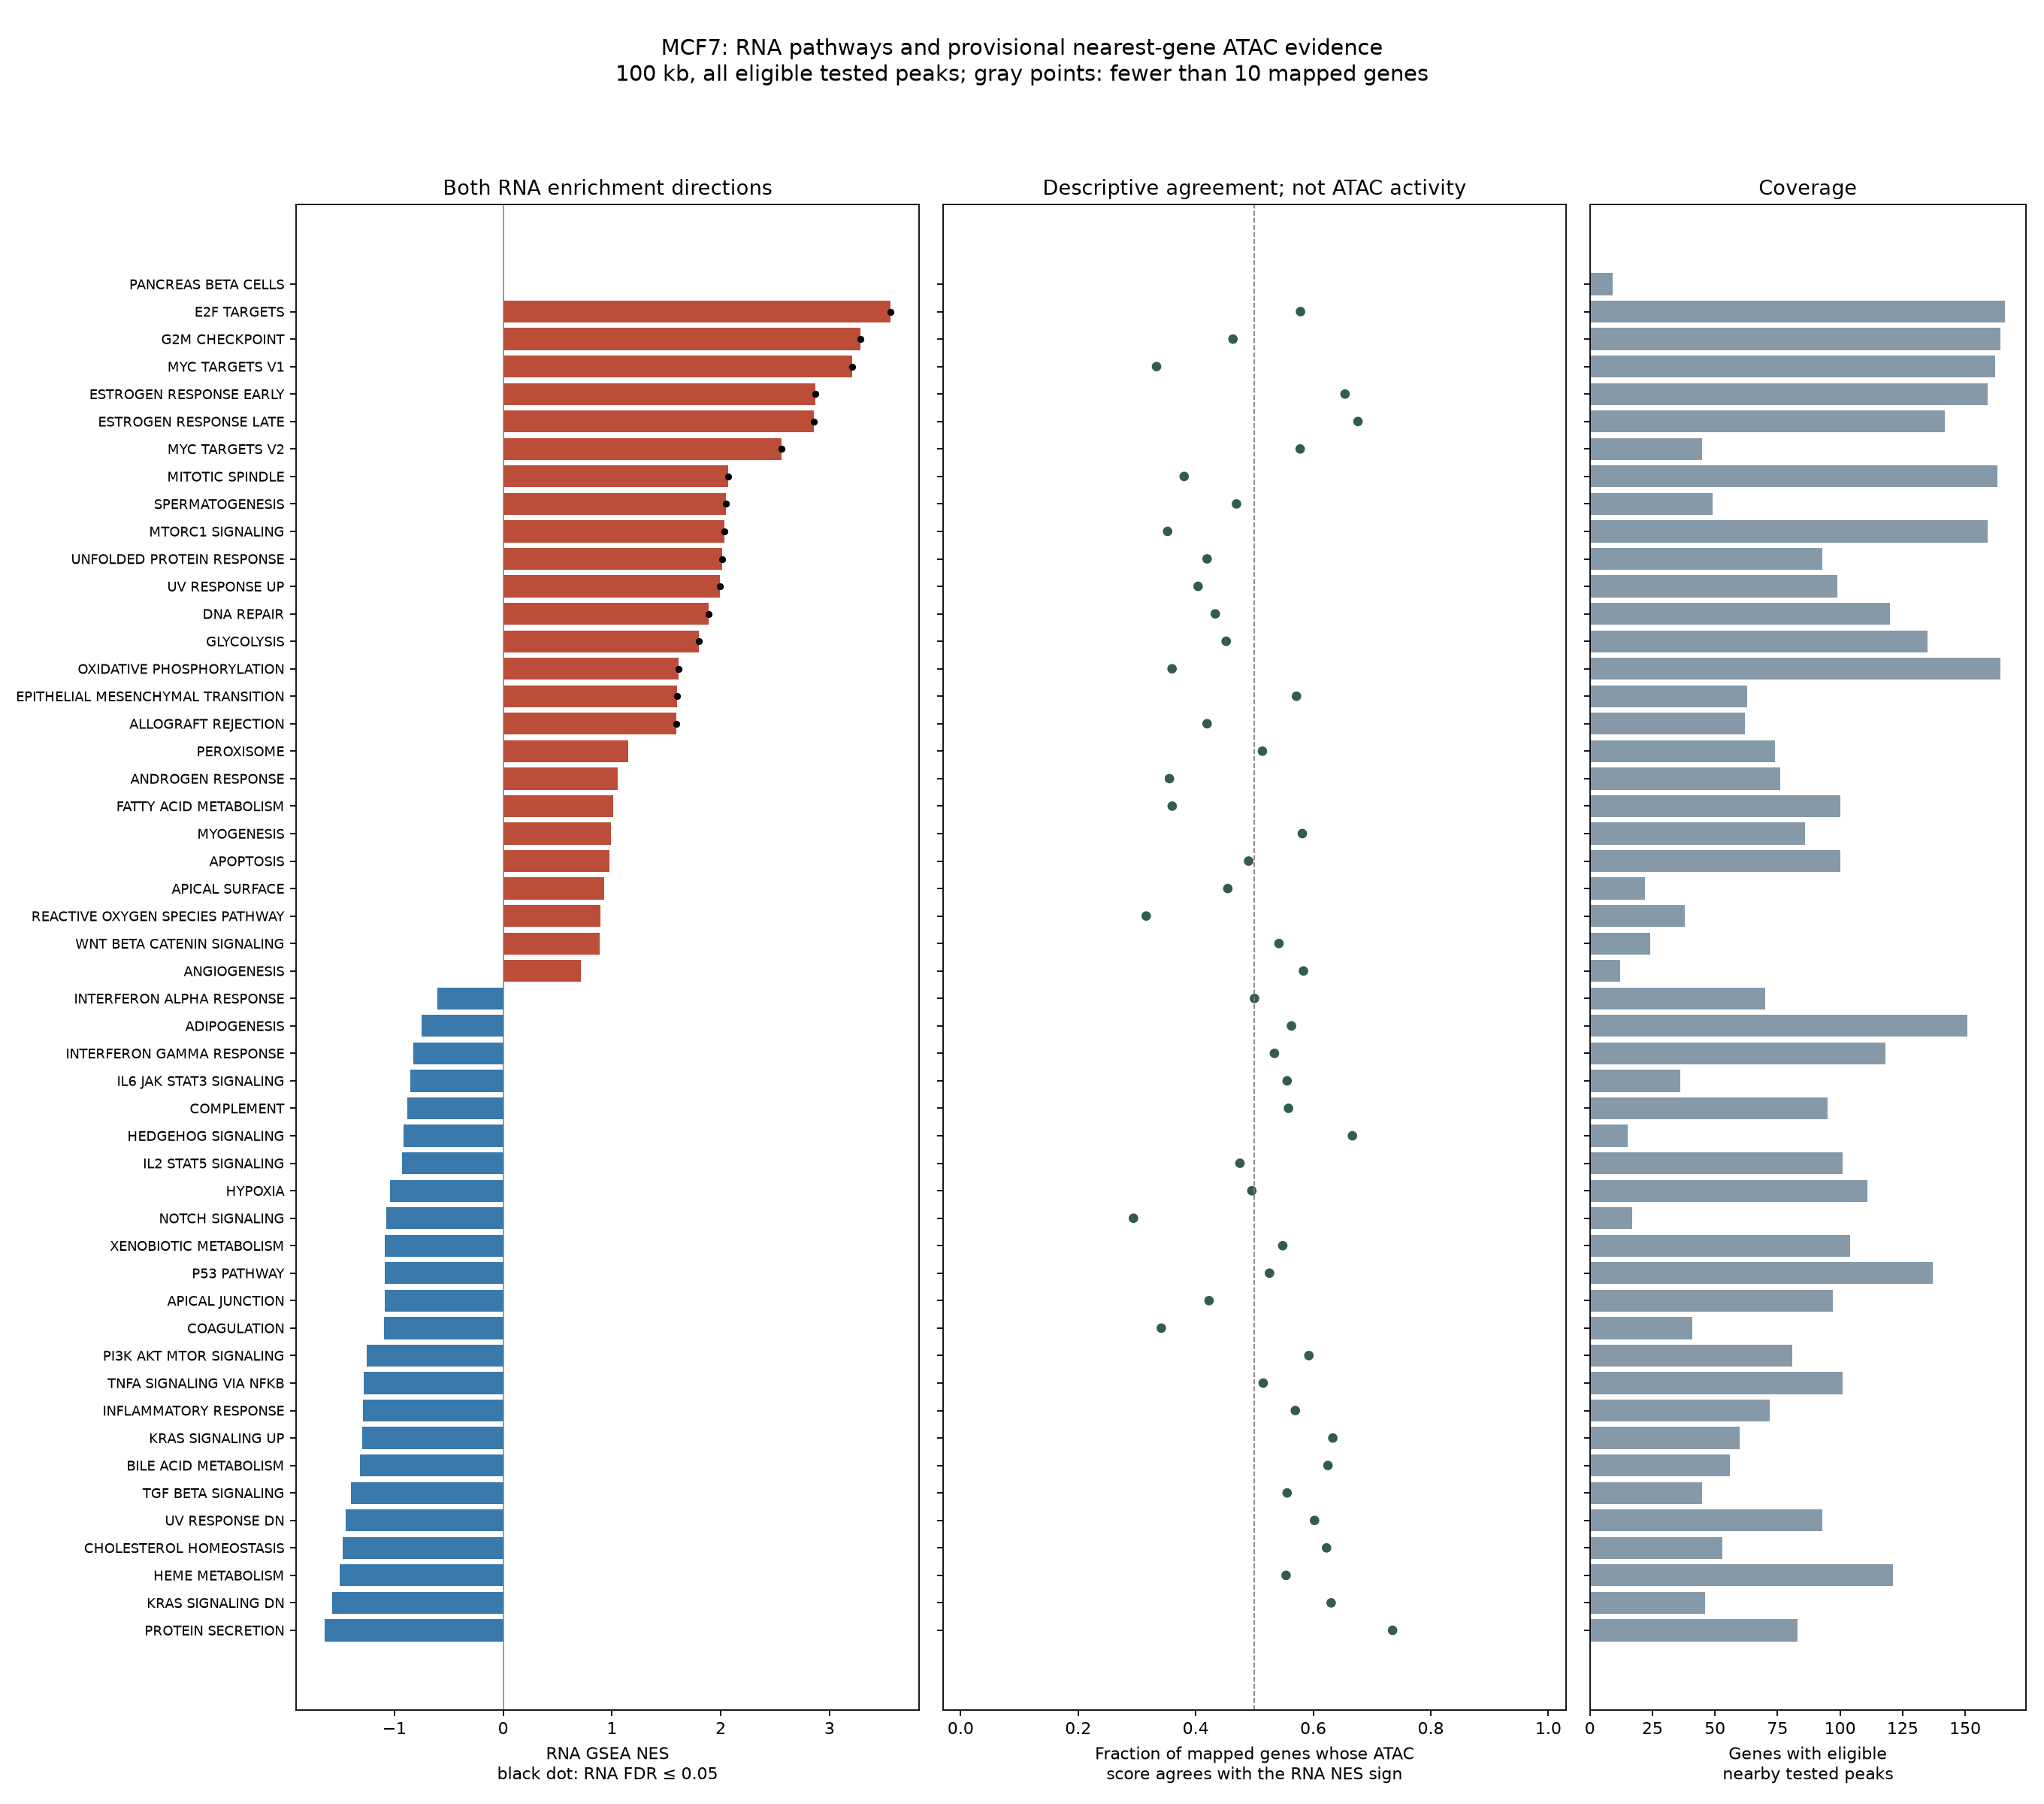

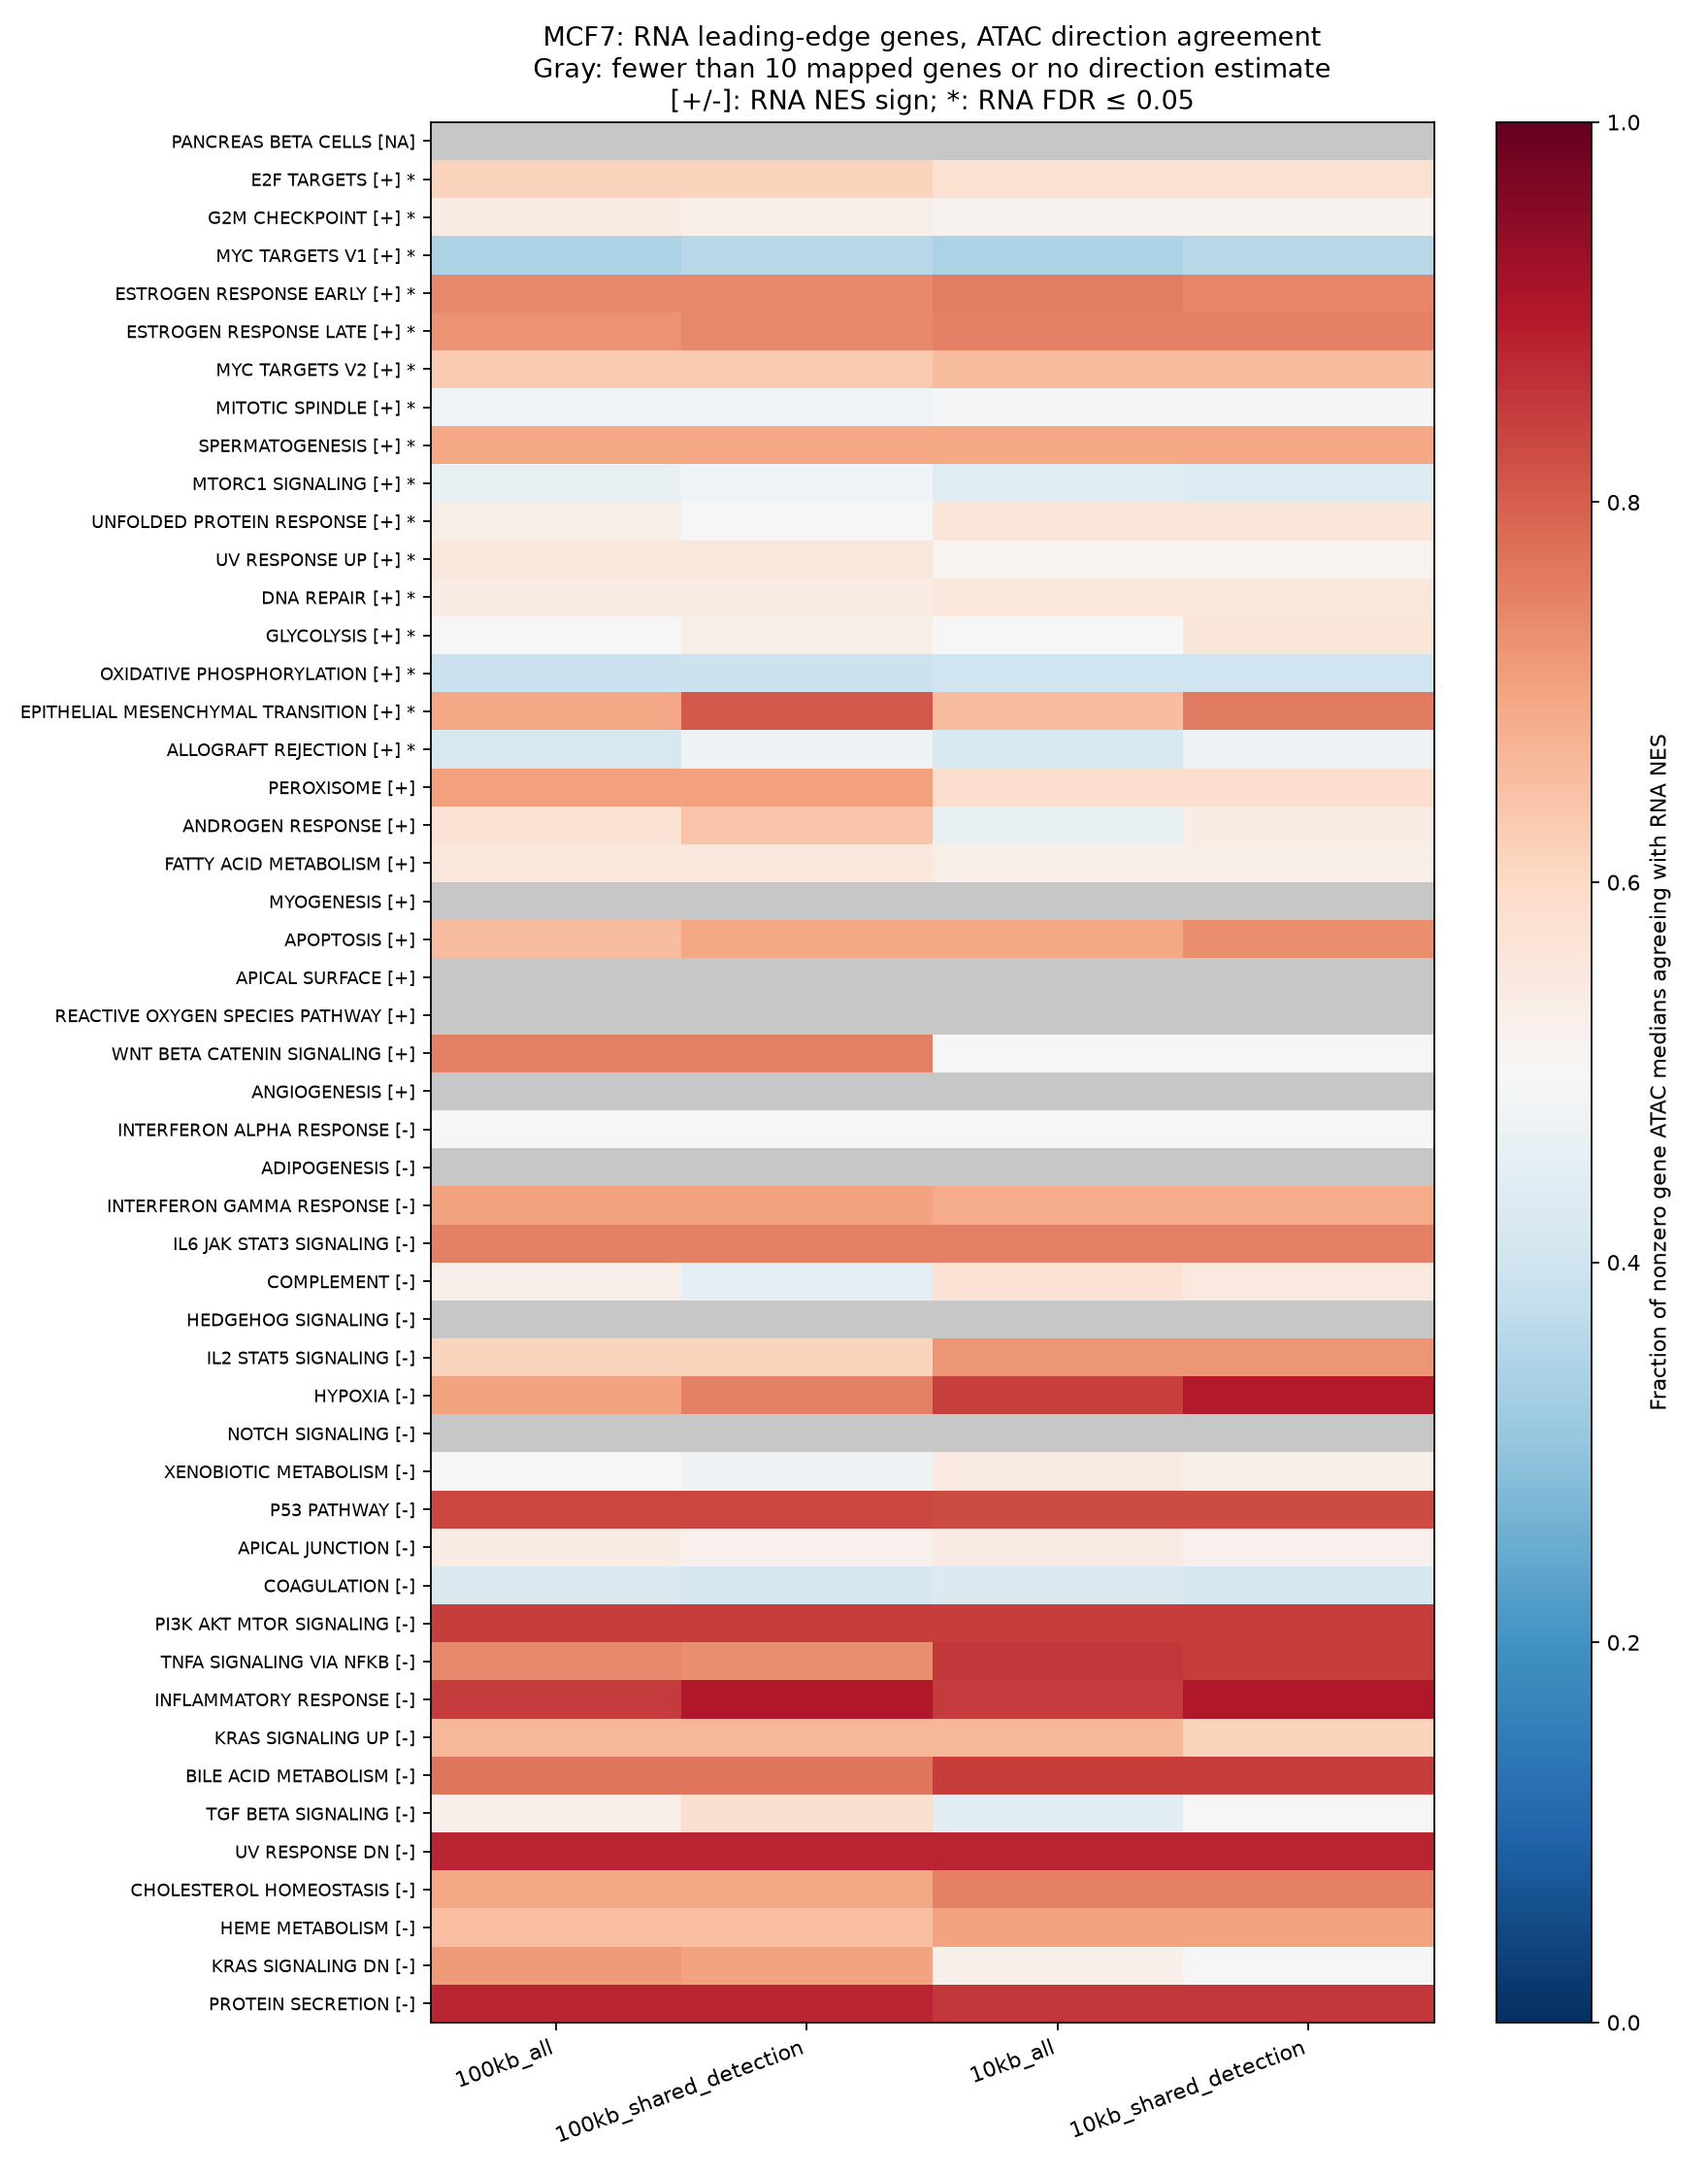

In [5]:
primary=summary.loc[(summary.cell_line=='MCF7')&(summary.scenario=='100kb_all')&(summary.subset=='all_members')]
columns=['pathway','rna_NES','rna_GSEA_FDR','n_RNA_tested_genes','n_ATAC_mapped_genes',
         'n_same_direction','n_opposite_direction','fraction_same_direction','direction_summary']
display(Markdown('**Positive RNA NES**'))
display(primary.loc[primary.rna_NES.gt(0)].nlargest(8,'rna_NES')[columns])
display(Markdown('**Negative RNA NES**'))
display(primary.loc[primary.rna_NES.lt(0)].nsmallest(8,'rna_NES')[columns])
for suffix in ('pathway_concordance','leading_edge_sensitivity'):
    display(Image(filename=str(BASE/'results/figures/nb06'/f'MCF7_{suffix}.png')))


### T47D

**Positive RNA NES**

,pathway,rna_NES,rna_GSEA_FDR,n_RNA_tested_genes,n_ATAC_mapped_genes,n_same_direction,n_opposite_direction,fraction_same_direction,direction_summary
452,HALLMARK_E2F_TARGETS,3.375331,0.0,194,165,64,101,0.387879,majority_opposite_direction
416,HALLMARK_G2M_CHECKPOINT,3.052105,0.0,191,168,63,105,0.375000,majority_opposite_direction
454,HALLMARK_MYC_TARGETS_V1,3.031695,0.0,199,167,54,113,0.323353,majority_opposite_direction
426,HALLMARK_ESTROGEN_RESPONSE_LATE,2.948248,0.0,166,159,94,65,0.591195,majority_same_direction
424,HALLMARK_ESTROGEN_RESPONSE_EARLY,2.931968,0.0,181,174,94,80,0.540230,majority_same_direction
456,HALLMARK_MYC_TARGETS_V2,2.500385,0.0,55,47,18,29,0.382979,majority_opposite_direction
446,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,2.231535,0.0,105,96,33,63,0.343750,majority_opposite_direction
450,HALLMARK_MTORC1_SIGNALING,2.192793,0.0,184,164,56,108,0.341463,majority_opposite_direction


**Negative RNA NES**

,pathway,rna_NES,rna_GSEA_FDR,n_RNA_tested_genes,n_ATAC_mapped_genes,n_same_direction,n_opposite_direction,fraction_same_direction,direction_summary
400,HALLMARK_TNFA_SIGNALING_VIA_NFKB,-2.318834,0.000000,125,120,87,33,0.725000,majority_same_direction
434,HALLMARK_INTERFERON_ALPHA_RESPONSE,-2.107240,0.000000,87,75,48,27,0.640000,majority_same_direction
436,HALLMARK_INTERFERON_GAMMA_RESPONSE,-1.985870,0.000486,145,125,86,39,0.688000,majority_same_direction
476,HALLMARK_UV_RESPONSE_DN,-1.918356,0.001458,115,109,74,35,0.678899,majority_same_direction
460,HALLMARK_INFLAMMATORY_RESPONSE,-1.674190,0.014291,78,75,47,28,0.626667,majority_same_direction
442,HALLMARK_HEDGEHOG_SIGNALING,-1.647661,0.014340,24,23,13,10,0.565217,majority_same_direction
438,HALLMARK_APICAL_JUNCTION,-1.609064,0.018124,111,98,51,47,0.520408,majority_same_direction
430,HALLMARK_MYOGENESIS,-1.587233,0.020416,91,85,47,38,0.552941,majority_same_direction


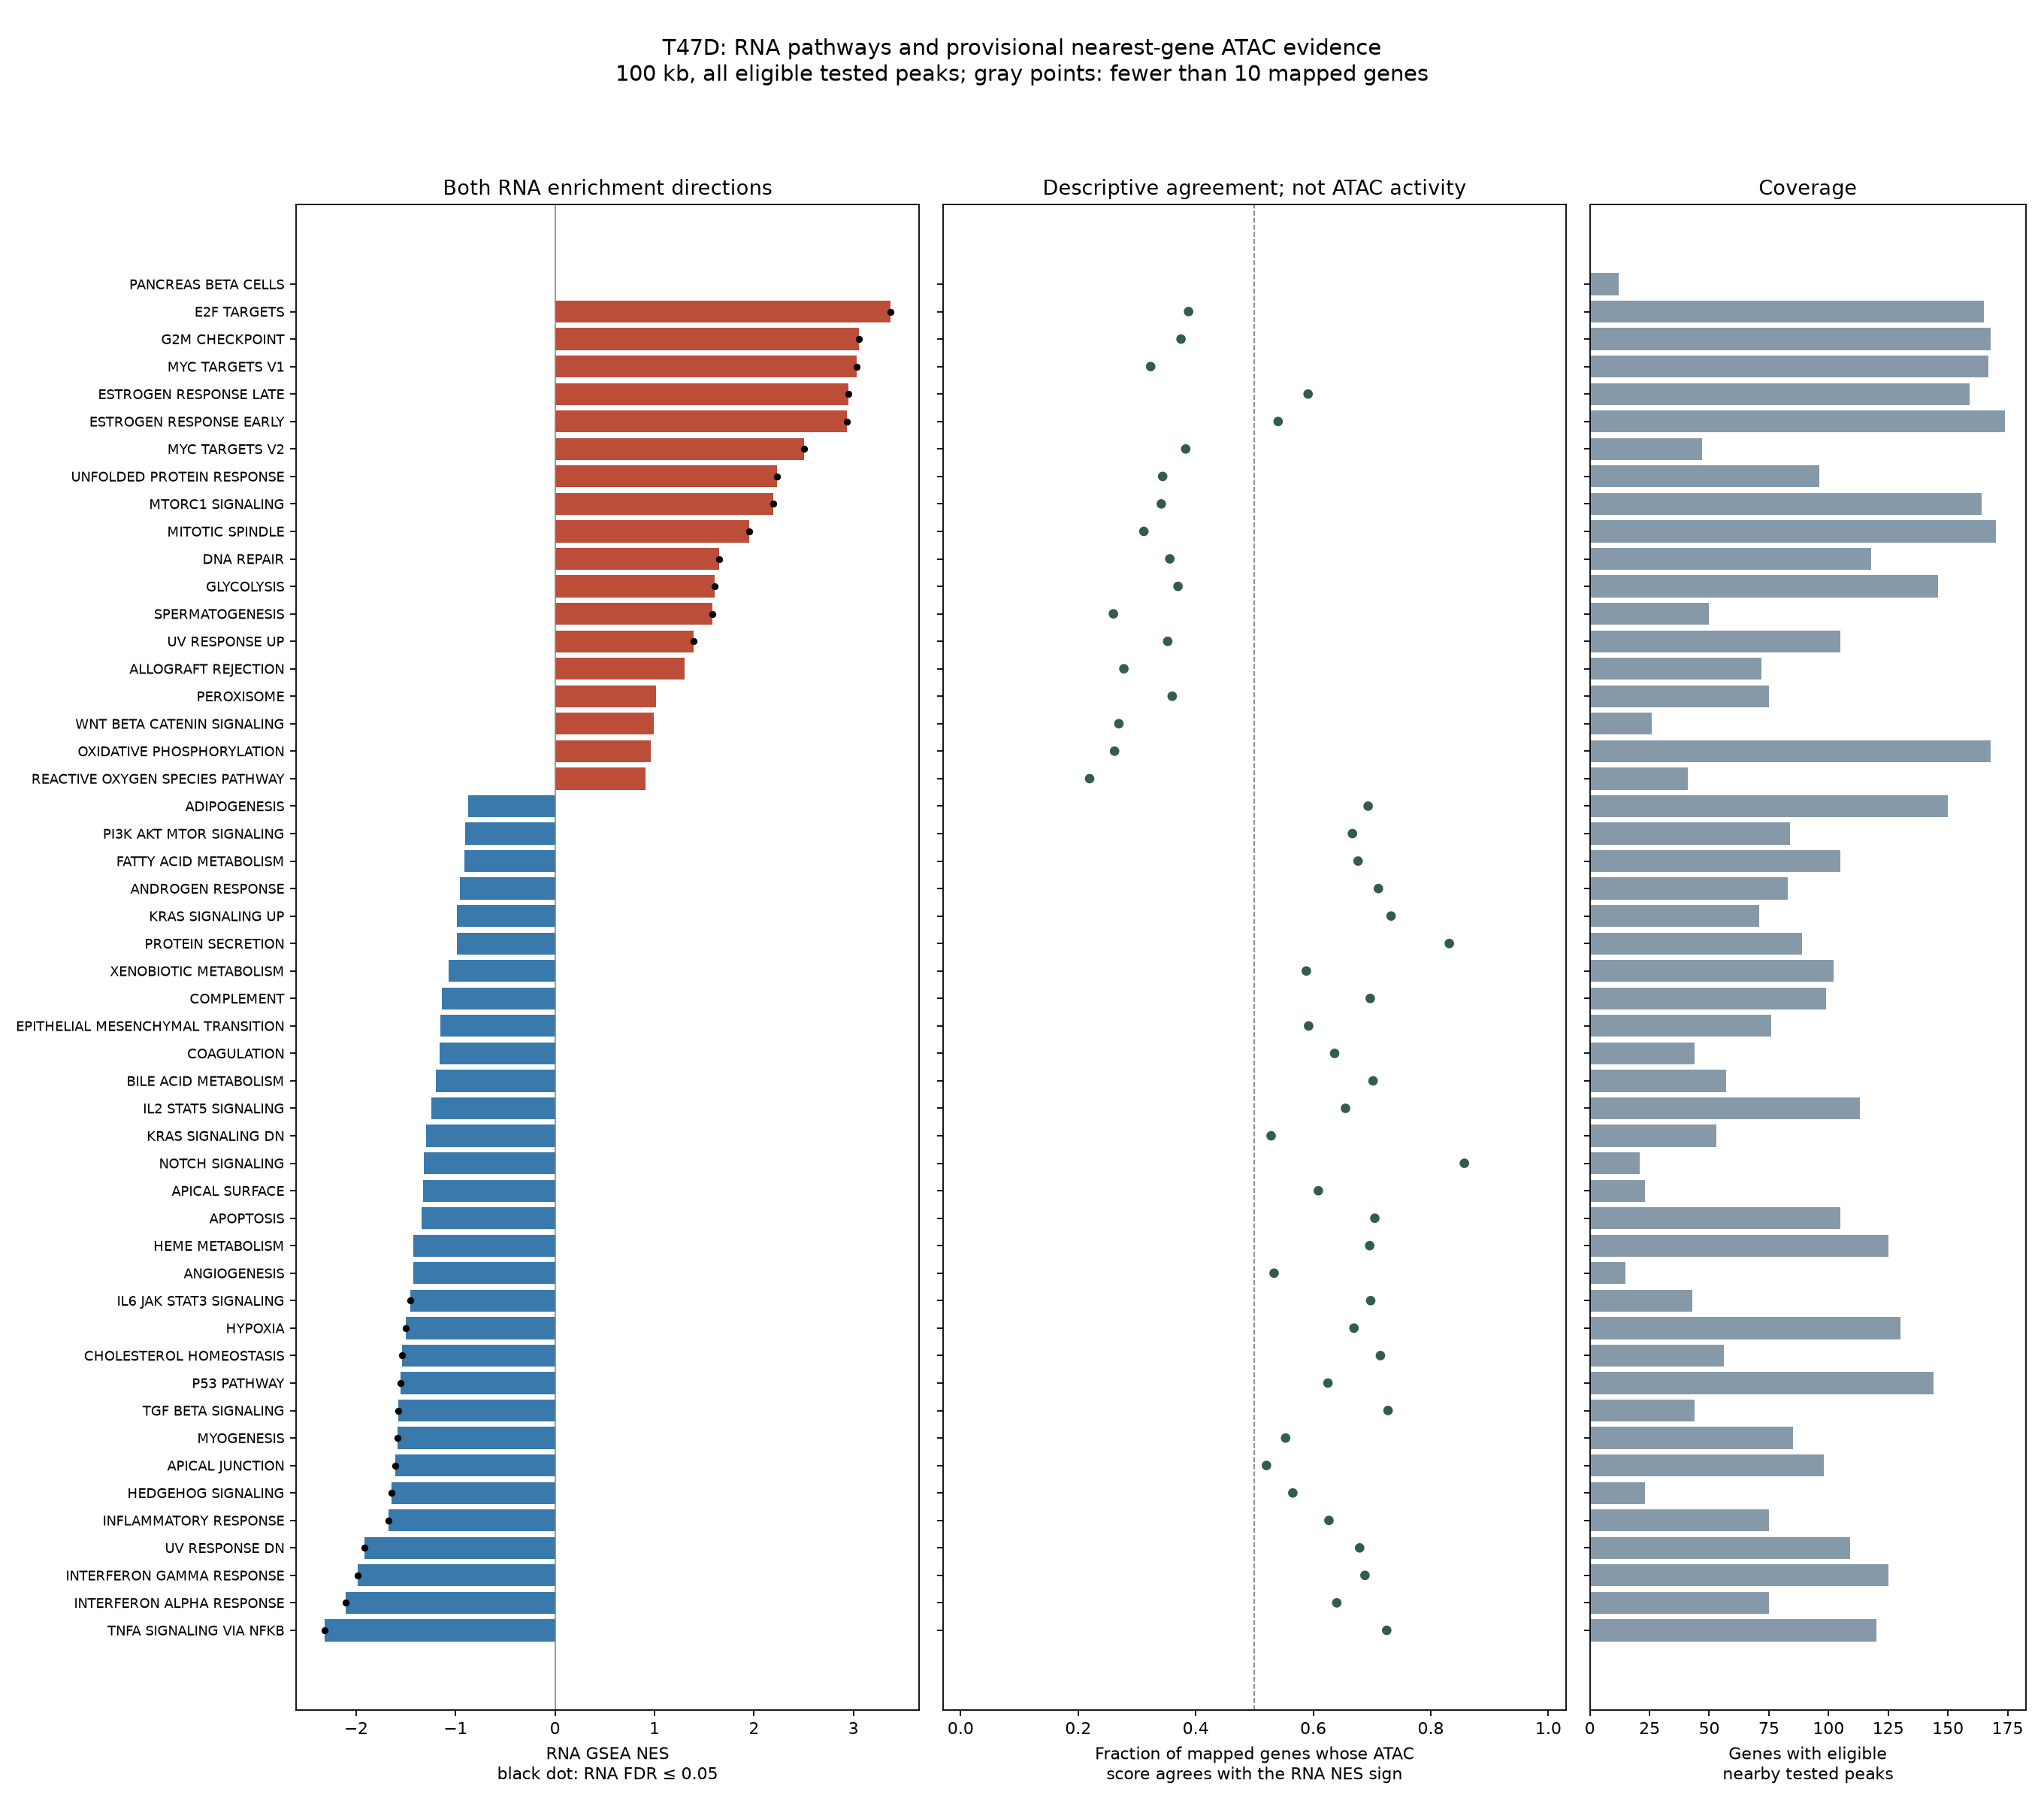

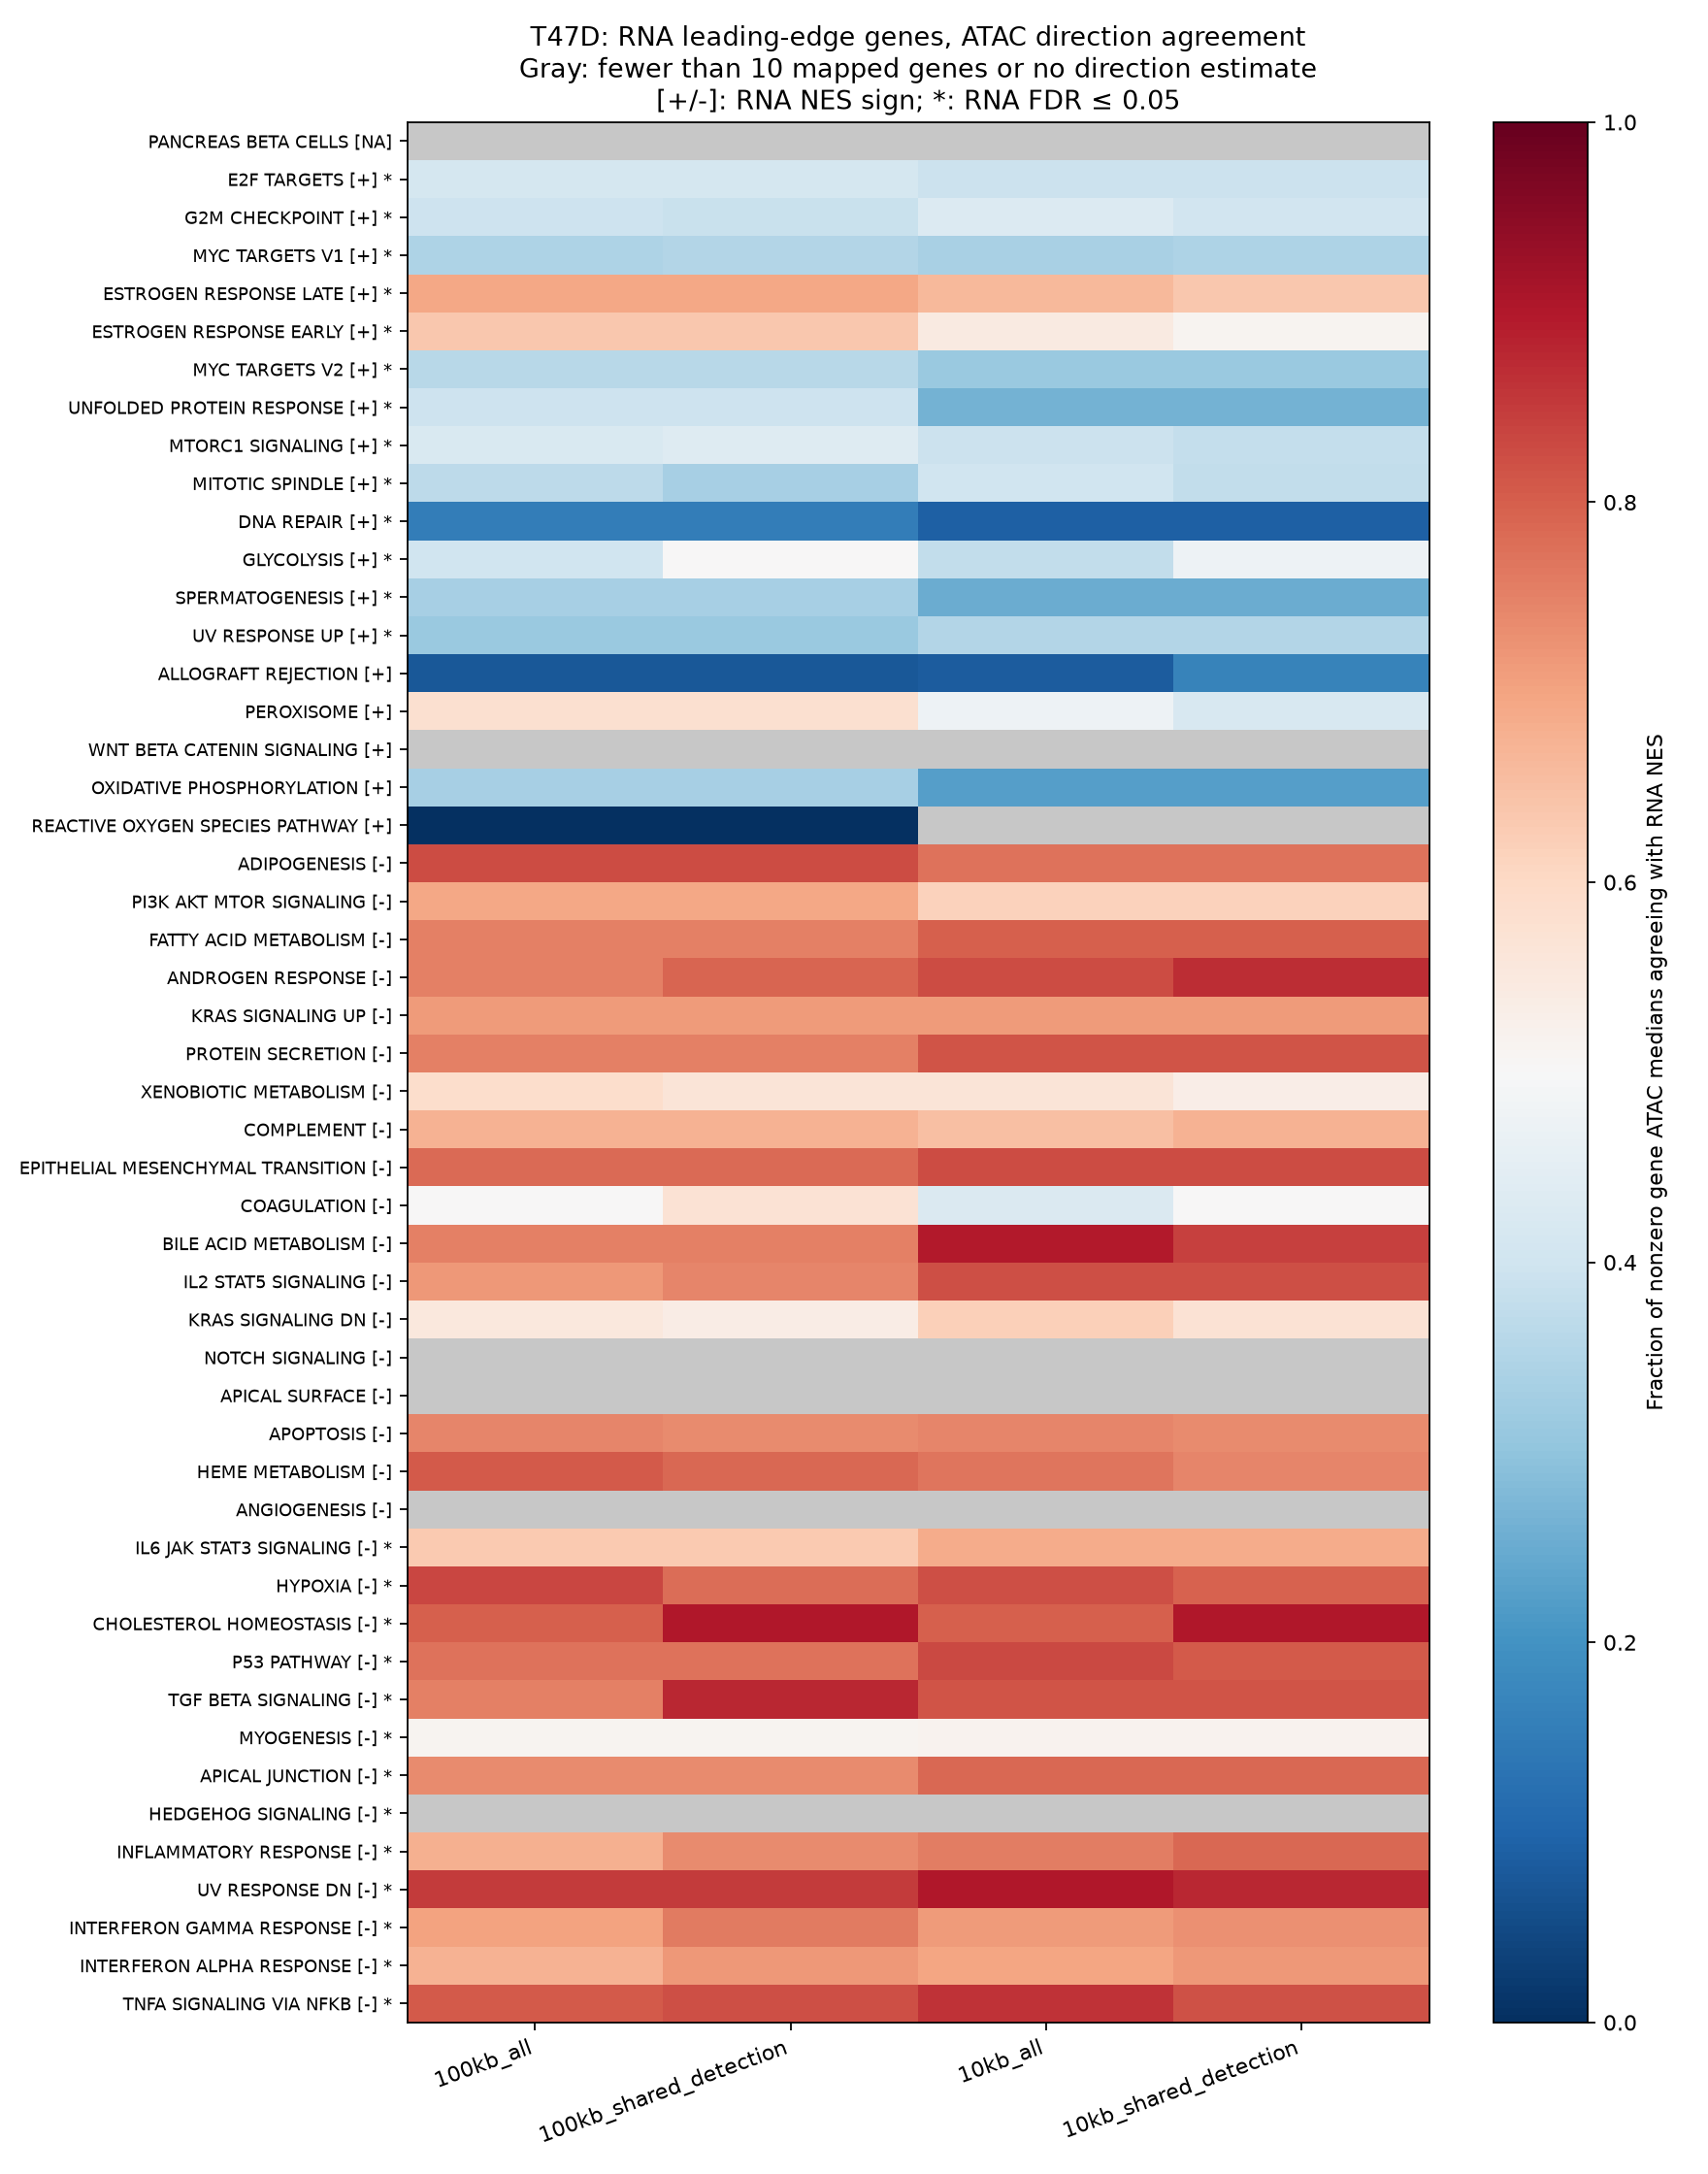

In [6]:
primary=summary.loc[(summary.cell_line=='T47D')&(summary.scenario=='100kb_all')&(summary.subset=='all_members')]
columns=['pathway','rna_NES','rna_GSEA_FDR','n_RNA_tested_genes','n_ATAC_mapped_genes',
         'n_same_direction','n_opposite_direction','fraction_same_direction','direction_summary']
display(Markdown('**Positive RNA NES**'))
display(primary.loc[primary.rna_NES.gt(0)].nlargest(8,'rna_NES')[columns])
display(Markdown('**Negative RNA NES**'))
display(primary.loc[primary.rna_NES.lt(0)].nsmallest(8,'rna_NES')[columns])
for suffix in ('pathway_concordance','leading_edge_sensitivity'):
    display(Image(filename=str(BASE/'results/figures/nb06'/f'T47D_{suffix}.png')))


## 5. Cross-line comparison and targeted gene evidence
Estrogen-response and cell-cycle rows are shown alongside both directions across
the full set. Inspect RNA fold changes and individual peak evidence before making
a biological claim. Shared directions do not imply independent replication.

In [7]:
selected=['HALLMARK_ESTROGEN_RESPONSE_EARLY','HALLMARK_ESTROGEN_RESPONSE_LATE',
          'HALLMARK_E2F_TARGETS','HALLMARK_G2M_CHECKPOINT']
comparison=cross_line.loc[(cross_line.scenario=='100kb_all')&(cross_line.subset=='all_members')]
display(comparison[['pathway','rna_NES_MCF7','rna_NES_T47D','fraction_same_direction_MCF7',
                    'fraction_same_direction_T47D','n_ATAC_mapped_genes_MCF7','n_ATAC_mapped_genes_T47D']])
display(summary.loc[summary.pathway.isin(selected),['cell_line','pathway','subset','scenario','rna_NES',
                    'n_ATAC_mapped_genes','fraction_same_direction','direction_summary']])
# Change these genes for focused inspection; an absent row means RNA was not tested.
for line in ('MCF7','T47D'):
    gene_table=pd.read_csv(BASE/f'results/tables/nb06/{line}_100kb_all_gene_evidence.tsv',sep='\t')
    display(gene_table.loc[gene_table.gene.isin(['ESR1','TFF1','GREB1','PGR','MYC','CCND1','ELOVL5'])])


,pathway,rna_NES_MCF7,rna_NES_T47D,fraction_same_direction_MCF7,fraction_same_direction_T47D,n_ATAC_mapped_genes_MCF7,n_ATAC_mapped_genes_T47D
0,HALLMARK_TNFA_SIGNALING_VIA_NFKB,-1.281805,-2.318834,0.514851,0.725000,101,120
2,HALLMARK_HYPOXIA,-1.043188,-1.500488,0.495495,0.669231,111,130
4,HALLMARK_CHOLESTEROL_HOMEOSTASIS,-1.476237,-1.540497,0.622642,0.714286,53,56
6,HALLMARK_MITOTIC_SPINDLE,2.066772,1.950390,0.380368,0.311765,163,170
8,HALLMARK_WNT_BETA_CATENIN_SIGNALING,0.889129,0.989111,0.541667,0.269231,24,26
10,HALLMARK_TGF_BETA_SIGNALING,-1.398422,-1.575026,0.555556,0.727273,45,44
12,HALLMARK_IL6_JAK_STAT3_SIGNALING,-0.852677,-1.455668,0.555556,0.697674,36,43
14,HALLMARK_DNA_REPAIR,1.888842,1.648564,0.433333,0.355932,120,118
16,HALLMARK_G2M_CHECKPOINT,3.282228,3.052105,0.463415,0.375000,164,168
18,HALLMARK_APOPTOSIS,0.976333,-1.343692,0.490000,0.704762,100,105


,cell_line,pathway,subset,scenario,rna_NES,n_ATAC_mapped_genes,fraction_same_direction,direction_summary
16,MCF7,HALLMARK_G2M_CHECKPOINT,all_members,100kb_all,3.282228,164,0.463415,majority_opposite_direction
17,MCF7,HALLMARK_G2M_CHECKPOINT,leading_edge,100kb_all,3.282228,106,0.537736,majority_same_direction
24,MCF7,HALLMARK_ESTROGEN_RESPONSE_EARLY,all_members,100kb_all,2.870268,159,0.654088,majority_same_direction
25,MCF7,HALLMARK_ESTROGEN_RESPONSE_EARLY,leading_edge,100kb_all,2.870268,73,0.739726,majority_same_direction
26,MCF7,HALLMARK_ESTROGEN_RESPONSE_LATE,all_members,100kb_all,2.857860,142,0.676056,majority_same_direction
...,...,...,...,...,...,...,...,...
725,T47D,HALLMARK_ESTROGEN_RESPONSE_EARLY,leading_edge,10kb_shared_detection,2.931968,97,0.515464,majority_same_direction
726,T47D,HALLMARK_ESTROGEN_RESPONSE_LATE,all_members,10kb_shared_detection,2.948248,154,0.506494,majority_same_direction
727,T47D,HALLMARK_ESTROGEN_RESPONSE_LATE,leading_edge,10kb_shared_detection,2.948248,82,0.634146,majority_same_direction
752,T47D,HALLMARK_E2F_TARGETS,all_members,10kb_shared_detection,3.375331,162,0.376543,majority_opposite_direction


,cell_line,scenario,gene,wilcoxon_score,approx_log2FC_E2_vs_Vehicle,cell_level_p,cell_level_BH_q,pct_E2,exploratory_candidate,direction,...,atac_median_score,atac_median_fraction_difference,n_positive_peaks,n_negative_peaks,n_condition_exclusive_peaks,n_candidate_positive,n_candidate_negative,mapped,mixed_peak_directions,rna_atac_direction_agrees
0,MCF7,100kb_all,TFF1,52.732544,3.103109,0.000000e+00,0.000000e+00,0.896625,True,higher_in_E2,...,10.264723,0.058704,1,0,0,1,0,True,False,True
1,MCF7,100kb_all,GREB1,51.276386,2.580852,0.000000e+00,0.000000e+00,0.927638,True,higher_in_E2,...,10.016055,0.051514,8,0,2,5,0,True,False,True
19,MCF7,100kb_all,PGR,33.293579,1.506887,4.782059e-243,1.921068e-240,0.953481,True,higher_in_E2,...,5.796060,0.038674,3,1,0,2,0,True,True,True
137,MCF7,100kb_all,CCND1,21.049915,1.324430,2.290878e-98,1.229895e-96,0.551535,True,higher_in_E2,...,2.096840,0.012745,6,1,0,0,0,True,True,True
903,MCF7,100kb_all,MYC,8.825264,1.360900,1.092018e-18,7.319911e-18,0.116753,True,higher_in_E2,...,0.867613,0.001836,2,1,0,1,0,True,True,True
1908,MCF7,100kb_all,ELOVL5,4.582272,0.223310,4.599515e-06,1.200635e-05,0.534509,False,higher_in_E2,...,3.280057,0.028472,2,1,1,1,0,True,True,True
2937,MCF7,100kb_all,ESR1,2.425062,0.085361,1.530576e-02,2.422719e-02,0.947400,False,higher_in_E2,...,1.074669,0.004068,7,2,0,0,0,True,True,True


,cell_line,scenario,gene,wilcoxon_score,approx_log2FC_E2_vs_Vehicle,cell_level_p,cell_level_BH_q,pct_E2,exploratory_candidate,direction,...,atac_median_score,atac_median_fraction_difference,n_positive_peaks,n_negative_peaks,n_condition_exclusive_peaks,n_candidate_positive,n_candidate_negative,mapped,mixed_peak_directions,rna_atac_direction_agrees
0,T47D,100kb_all,GREB1,53.869465,2.627995,0.000000e+00,0.000000e+00,0.940252,True,higher_in_E2,...,10.996718,0.065358,9,2,4,6,2,True,True,True
1,T47D,100kb_all,TFF1,51.688732,2.949219,0.000000e+00,0.000000e+00,0.975596,True,higher_in_E2,...,10.620853,0.066695,6,0,2,4,0,True,False,True
4,T47D,100kb_all,PGR,42.023193,2.467491,0.000000e+00,0.000000e+00,0.795512,True,higher_in_E2,...,5.797822,0.027488,2,1,0,1,0,True,True,True
697,T47D,100kb_all,CCND1,9.242831,0.385271,2.400595e-20,2.223022e-19,0.707994,False,higher_in_E2,...,0.834773,-0.002658,6,0,0,0,0,True,False,True
724,T47D,100kb_all,ELOVL5,9.026435,0.529209,1.773549e-19,1.570369e-18,0.451332,True,higher_in_E2,...,1.829712,0.004685,2,1,1,1,0,True,True,True
5088,T47D,100kb_all,MYC,0.341754,0.151622,7.325362e-01,7.865904e-01,0.185975,False,higher_in_E2,...,-0.920661,-0.009986,2,4,0,0,1,True,True,False
11904,T47D,100kb_all,ESR1,-25.720530,-0.703425,6.889596e-146,1.824671e-143,0.955961,True,higher_in_Vehicle,...,-0.424781,-0.010600,7,8,0,0,0,True,True,True


## 6. What can we conclude?
Agreement is a candidate coordinated RNA/accessibility response. Disagreement
can reflect different regulatory mechanisms, timing, imperfect target assignment,
or technical effects. Neither outcome establishes pathway activation or inhibition.

Before prioritizing a pathway, check both signs of RNA NES, the RNA FDR, mapped
gene counts, the leading-edge subset, mixed peak directions, and all four sensitivity
scenarios. Use the full peak/gene evidence tables to trace each summary back to
upstream statistics. Biological replication and validated peak-gene links remain
needed for stronger conclusions.


## Initial run findings (10 October 2026)

These are descriptive observations from the saved run; the tables above are the
authoritative outputs if the notebook is rerun with changed inputs.

| Cell line | Positive RNA NES | Negative RNA NES | Positive RNA FDR <= 0.05 | Negative RNA FDR <= 0.05 |
|---|---:|---:|---:|---:|
| MCF7 | 25 | 24 | 16 | 0 |
| T47D | 18 | 31 | 13 | 13 |

One of the 50 Hallmarks was not tested in each line by nb04 and retains an
undefined RNA direction here. Negative NES alone does not establish a reduced
expression signature at the chosen FDR threshold; in particular, **none of the
negative MCF7 pathways meets RNA FDR <= 0.05**.

With the primary 100 kb mapping, 9,316 of 11,650 RNA-tested MCF7 genes and 9,706 of
11,918 T47D genes have eligible nearby tested peaks. Unmapped genes remain missing
evidence, not evidence of unchanged accessibility.

For the RNA leading-edge genes of estrogen response early/late, the fractions of
mapped genes with ATAC medians agreeing with positive RNA NES are approximately
74% / 72% in MCF7 and 64% / 69% in T47D. Under the tighter 10 kb mapping with
condition-exclusive peaks removed, they are 74% / 75% and 52% / 63%, respectively.
Thus the early estrogen-response concordance in T47D is sensitive to mapping
choices and becomes close to evenly split. These fractions are not effect sizes,
ATAC enrichment statistics, or probabilities of pathway activation.

Inspect all pathways, including opposing directions, and the coverage and gene
tables before prioritization. No replicate-supported or causal regulatory claim
follows from these descriptive summaries.
